# Faz 3 — Keşifsel veri analizi (EDA)

Bu notebook vize kriteri **6**'yı karşılar: her modalite için görsel analiz, istatistiksel dağılım analizi,
modaliteler arası ilişkiler, aykırı durum analizi ve bilimsel yorum.

**Girdi:** Faz 2 çıktıları (`veri/islenmis/temiz_cagrilar.parquet`, `seri_girdisi.npz`), Faz 1 fiyat pencereleri,
SPY fiyatı ve Loughran–McDonald (LM) sözlüğü (`src/indir.py` indirir). Süre ~2 dk.

**Sızıntıya karşı kural:** Modelleme kararlarını yönlendirebilecek her analiz (kelime listeleri, özellik–sınıf
ilişkileri, korelasyonlar) yalnız **eğitim döneminde** (çağrı tarihi ≤ 2016-12-31, n = 1.866) yapılır. 2017–2018
verisi yalnız dağılımın zamanla kayıp kaymadığını göstermek için kullanılır. Böylece test dönemi, model kurulmadan
önce "görülmüş" olmaz.

**Özet özellikler hakkında:** Aşağıdaki özet özellikler (ör. geçmiş oynaklık, sözlük sıklıkları) yalnız analiz
içindir. Final modelinde fiyat modalitesi 60 × 3 diziyi, metin modalitesi metnin kendisini okuyacak.

In [1]:
import sys
import textwrap
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats

from src import etiket, ozellik, veri
from src.istatistik import kismi, kw, metin_komsulari, sirket_ornekleri

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
SINIF_RENK = ["#6da7ec", "#2a78d6", "#104281"]
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.titlesize": 11})
pd.set_option("display.width", 170)
SINIF = etiket.SINIF_ADLARI


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".")


VIRGUL = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))


def pyaz(p):
    """p-değerini okunur yazar; kayan nokta alt sınırının altındaysa '< 1e-300'."""
    return "p < 1e-300" if p == 0 else (f"p = {tr(p, 3)}" if p >= 0.001 else f"p = {p:.1e}")

## 1. Analiz için özet özellikler

| Modalite | Özellik | Tanım |
|---|---|---|
| Metin | `belirsizlik`, `olumsuz`, `olumlu`, `hukuki`, `kisitlayici`, `zayif_kip`, `guclu_kip` | LM sözlüğünün ilgili kategorisindeki kelimelerin 1.000 kelimedeki sıklığı |
| Metin | `net_ton` | (olumlu − olumsuz) / (olumlu + olumsuz) |
| Metin | `n_kelime`, `sayisal` | Kelime sayısı; 1.000 kelimedeki sayısal ifade ($, %, rakam) |
| Metin | `komsu_v` | Bölüm 5.1'de: metni en çok benzeyen 10 *farklı başka şirketin* (her birinden en benzer tek çağrı) hedef oynaklık ortalaması |
| Fiyat | `gecmis_oyn_60`, `gecmis_oyn_5` | Gün −60..−1 ve −5..−1 getirilerinin ln(std)'si (hedefle aynı dönüşüm) |
| Fiyat | `aralik_ort` | Gün içi aralığın (ln Y/D) 60 günlük ortalamasının logu |
| Fiyat | `hacim_son5`, `getiri_60` | Son 5 günün göreli log hacim ortalaması; 60 günlük toplam log getiri |
| Piyasa | `piyasa_once` | SPY'nin gün −20..−1 getirilerinin ln(std)'si (çağrı anında bilinir) |
| Piyasa | `piyasa_hedef` | SPY'nin gün 0..+6 getirilerinin ln(std)'si — **çağrı anında bilinmez**, yalnız karıştırıcı etki analizinde |

In [2]:
t = pd.read_parquet(ISLENMIS / "temiz_cagrilar.parquet")
z = np.load(ISLENMIS / "seri_girdisi.npz", allow_pickle=True)
X = z["X"]
assert (z["klasor"] == t.klasor.to_numpy()).all(), "metin ve seri sırası aynı olmalı"
sozluk = ozellik.lm_sozluk()
print("LM kategori boyutları:", {k: len(v) for k, v in sozluk.items()})
spy = veri.fiyat_oku(veri.fiyat_dosyalari()["SPY"])
d = pd.concat([t[["klasor", "tarih", "ticker", "t0", "v", "sinif", "bolum"]].reset_index(drop=True),
               ozellik.metin_ozellikleri(t.cumleler_temiz, sozluk), ozellik.fiyat_ozet(X)], axis=1)
d["piyasa_once"] = ozellik.piyasa_oynakligi(spy, d.t0, -20, -1)
d["piyasa_hedef"] = ozellik.piyasa_oynakligi(spy, d.t0, 0, 6)
d["bolum"] = d.bolum.fillna("bilinmiyor")
d["donem"] = np.where(d.tarih <= "2016-12-31", "eğitim (≤2016)", "sonrası (2017–2018)")
e = d[d.donem == "eğitim (≤2016)"].reset_index(drop=True)
print(f"Toplam: {len(d):,} çağrı | eğitim dönemi: {len(e):,} | sonrası: {len(d) - len(e):,}")
print("Eğitim döneminde sınıflar:", e.sinif.value_counts().sort_index().to_dict())

LM kategori boyutları: {'olumsuz': 2355, 'olumlu': 354, 'belirsizlik': 297, 'hukuki': 905, 'kisitlayici': 184, 'zayif_kip': 27, 'guclu_kip': 19}


Toplam: 3,000 çağrı | eğitim dönemi: 1,866 | sonrası: 1,134
Eğitim döneminde sınıflar: {0: 622, 1: 622, 2: 622}


## 2. Metin modalitesi

### 2.1 Sözlük temelli ton ve sınıflar
Finans metinlerinde en yaygın ölçü, Loughran–McDonald sözlüğüyle sayılan belirsizlik, olumsuzluk ve ton
oranlarıdır. Bu oranların sınıflar arasında farklı olup olmadığına bakılır.

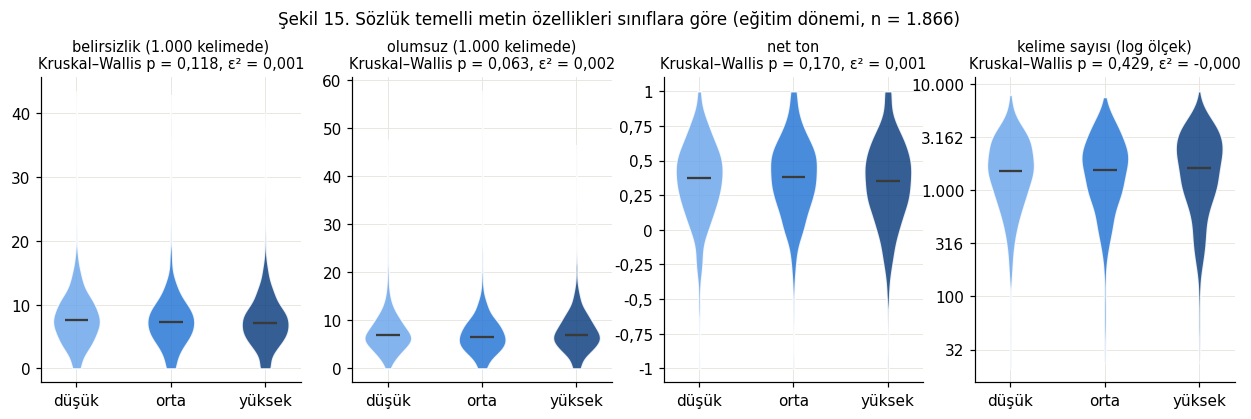

belirsizlik  Spearman(v) = -0.061 | KW p = 0.118 | ε² = 0.0012
olumsuz      Spearman(v) = +0.010 | KW p = 0.0632 | ε² = 0.0019
olumlu       Spearman(v) = -0.011 | KW p = 0.759 | ε² = -0.0008
net_ton      Spearman(v) = -0.022 | KW p = 0.17 | ε² = 0.0008
hukuki       Spearman(v) = -0.061 | KW p = 0.00309 | ε² = 0.0051
kisitlayici  Spearman(v) = +0.023 | KW p = 0.667 | ε² = -0.0006
zayif_kip    Spearman(v) = -0.051 | KW p = 0.212 | ε² = 0.0006
sayisal      Spearman(v) = -0.006 | KW p = 0.876 | ε² = -0.0009
n_kelime     Spearman(v) = +0.030 | KW p = 0.429 | ε² = -0.0002


In [3]:
oz = ["belirsizlik", "olumsuz", "net_ton", "n_kelime"]
adlar = {"belirsizlik": "belirsizlik (1.000 kelimede)", "olumsuz": "olumsuz (1.000 kelimede)", "net_ton": "net ton",
         "n_kelime": "kelime sayısı (log ölçek)"}
fig, eksen = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, k in zip(eksen, oz):
    deger = [np.log10(e.loc[e.sinif == c, k]) if k == "n_kelime" else e.loc[e.sinif == c, k] for c in range(3)]
    vp = ax.violinplot(deger, showmedians=True, showextrema=False)
    for b, renk in zip(vp["bodies"], SINIF_RENK):
        b.set_facecolor(renk); b.set_alpha(0.85); b.set_edgecolor("white")
    vp["cmedians"].set_color(KOYU)
    H, p, eps = kw(e, k)
    ax.set_title(f"{adlar[k]}\nKruskal–Wallis {pyaz(p)}, ε² = {tr(eps, 3)}", fontsize=9.5)
    ax.set_xticks([1, 2, 3], SINIF)
    if k == "n_kelime":
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: tr(10 ** x)))
    else:
        ax.yaxis.set_major_formatter(VIRGUL)
fig.suptitle(f"Şekil 15. Sözlük temelli metin özellikleri sınıflara göre (eğitim dönemi, n = {tr(len(e))})", y=1.05, fontsize=11)
kaydet(fig, "f3_01_sozluk_siniflar")
plt.show()
for k in ["belirsizlik", "olumsuz", "olumlu", "net_ton", "hukuki", "kisitlayici", "zayif_kip", "sayisal", "n_kelime"]:
    H, p, eps = kw(e, k)
    print(f"{k:12s} Spearman(v) = {stats.spearmanr(e[k], e.v)[0]:+.3f} | KW p = {p:.3g} | ε² = {eps:.4f}")

**Ne gözlendi:** Sözlük temelli belirsizlik, olumsuzluk ve net ton oranlarının dağılımları üç sınıfta neredeyse
üst üste biniyor. Etki büyüklükleri (ε²) sıfıra çok yakın (en büyüğü 0,005), hedefle sıra korelasyonlarının mutlak değeri 0,07'nin altında; metin uzunluğu
da sınıfları ayırmıyor.

**Neden önemli:** Bu bir "olumsuz bulgu" ama önemli: bu veride metnin oynaklık bilgisi, yönetimin konuşmasındaki
genel duygu tonunda değil. Olası nedenler: metin yalnız yönetim konuşması (yöneticiler tonu bilinçli olarak dengeli
tutar), ufuk kısa (7 işlem günü) ve oranlar konuşmanın ne hakkında olduğunu değil nasıl söylendiğini ölçüyor.

**Sonraki aşamaya etkisi:** Metin modalitesi için sözlük sayımı gibi basit özellikler yetmez; içeriği temsil eden
gösterimler (TF-IDF, dil modeli gömmeleri) gerekir. Bölüm 2.2 ve 5.1 metnin bilgisinin nerede olduğunu inceliyor.

### 2.2 Sınıfları ayıran kelimeler ve sektör etkisi
Her kelime için, kelimeyi içeren çağrıların payı yüksek ve düşük sınıfta ayrı hesaplanır (belge sıklığı); fark en
büyük olan kelimeler listelenir. En az 40 çağrıda geçen kelimeler alınır (nadir kelimelerin gürültüsünü önlemek için).

Aday kelime: 3,052 | yüksek sınıf çağrısı: 622 | düşük sınıf çağrısı: 622


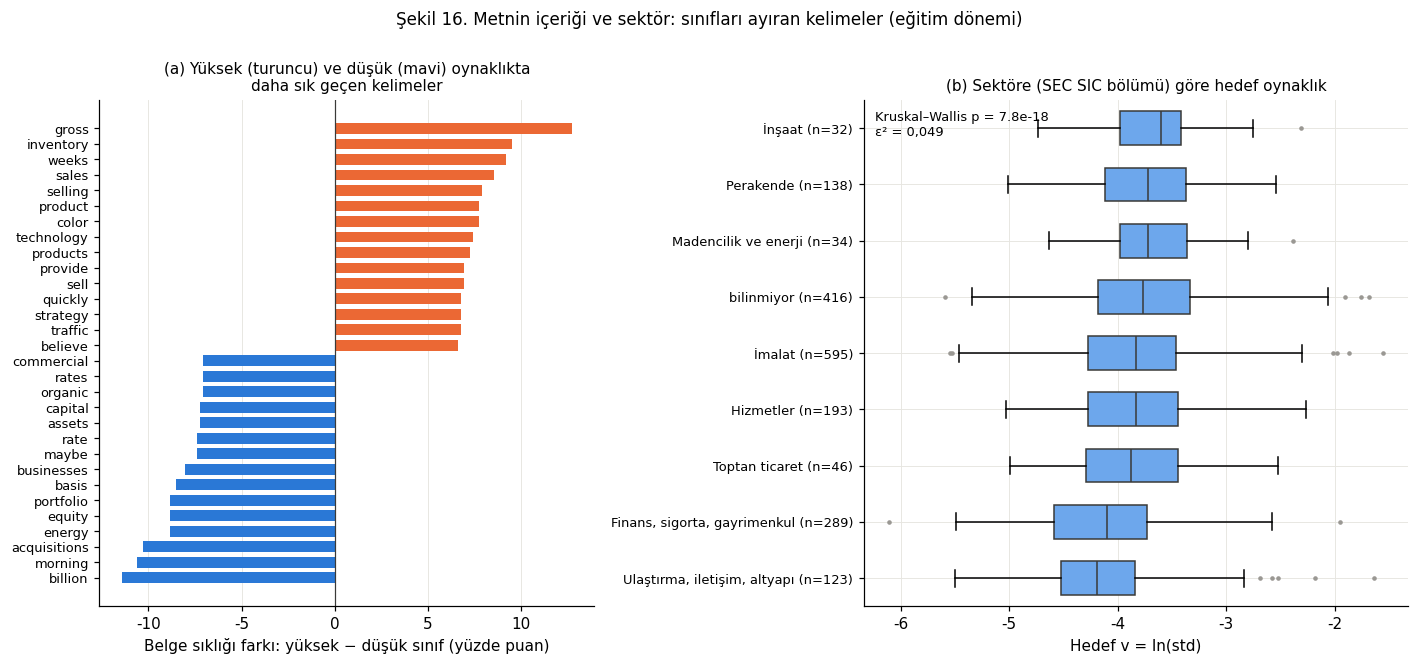

Yüksek sınıfta daha sık (yüzde puan): {'gross': 12.7, 'inventory': 9.5, 'weeks': 9.2, 'sales': 8.5, 'selling': 7.9, 'product': 7.7, 'color': 7.7, 'technology': 7.4, 'products': 7.2, 'provide': 6.9, 'sell': 6.9, 'quickly': 6.8, 'strategy': 6.8, 'traffic': 6.8, 'believe': 6.6}
Düşük sınıfta daha sık (yüzde puan): {'billion': -11.4, 'morning': -10.6, 'acquisitions': -10.3, 'energy': -8.8, 'equity': -8.8, 'portfolio': -8.8, 'basis': -8.5, 'businesses': -8.0, 'maybe': -7.4, 'rate': -7.4, 'assets': -7.2, 'capital': -7.2, 'organic': -7.1, 'rates': -7.1, 'commercial': -7.1}
Sektör medyanları: {'Ulaştırma, iletişim, altyapı': -4.19, 'Finans, sigorta, gayrimenkul': -4.1, 'Toptan ticaret': -3.88, 'Hizmetler': -3.83, 'İmalat': -3.83, 'bilinmiyor': -3.77, 'Madencilik ve enerji': -3.72, 'Perakende': -3.72, 'İnşaat': -3.6}


In [4]:
import re
from collections import Counter

kelime_kumeleri = [set(re.findall(r"[a-z]{3,}", " ".join(s).lower())) - {"name", "url"} for s in t.cumleler_temiz]
kume = pd.Series(kelime_kumeleri, index=t.klasor)
egitim_k = e.klasor
yuksek, dusuk = egitim_k[e.sinif == 2], egitim_k[e.sinif == 0]
sayac = {}
for grup, ad in [(yuksek, "y"), (dusuk, "d"), (egitim_k, "t")]:
    sayac[ad] = Counter(w for k in grup for w in kume[k])
kelimeler = [w for w, n in sayac["t"].items() if n >= 40]
fark = pd.Series({w: 100 * (sayac["y"][w] / len(yuksek) - sayac["d"][w] / len(dusuk)) for w in kelimeler}).sort_values()
ust = pd.concat([fark.head(15), fark.tail(15)])
print(f"Aday kelime: {len(kelimeler):,} | yüksek sınıf çağrısı: {len(yuksek)} | düşük sınıf çağrısı: {len(dusuk)}")

sektor = e.groupby("bolum").v.agg(["median", "size"]).query("size >= 20").sort_values("median")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.1]})
a1.barh(range(len(ust)), ust.values, color=[MAVI if x < 0 else TURUNCU for x in ust.values], height=0.7)
a1.set_yticks(range(len(ust)), ust.index, fontsize=8.5)
a1.axvline(0, color=KOYU, lw=0.8)
a1.set_xlabel("Belge sıklığı farkı: yüksek − düşük sınıf (yüzde puan)")
a1.set_title("(a) Yüksek (turuncu) ve düşük (mavi) oynaklıkta\ndaha sık geçen kelimeler", fontsize=10)
a1.grid(axis="y", visible=False)
a1.xaxis.set_major_formatter(VIRGUL)
bp = a2.boxplot([e.loc[e.bolum == b, "v"] for b in sektor.index], vert=False, patch_artist=True, widths=0.6,
                medianprops={"color": KOYU}, flierprops={"markersize": 2, "markerfacecolor": GRI, "markeredgecolor": GRI})
for b in bp["boxes"]:
    b.set_facecolor(SINIF_RENK[0]); b.set_edgecolor(KOYU)
a2.set_yticks(range(1, len(sektor) + 1), [f"{b} (n={n})" for b, n in zip(sektor.index, sektor["size"])], fontsize=8.5)
a2.set_xlabel("Hedef v = ln(std)")
a2.set_title("(b) Sektöre (SEC SIC bölümü) göre hedef oynaklık", fontsize=10)
a2.xaxis.set_major_formatter(VIRGUL)
H, p = stats.kruskal(*[e.loc[e.bolum == b, "v"] for b in sektor.index])
a2.text(0.02, 0.98, f"Kruskal–Wallis {pyaz(p)}\nε² = {tr((H - len(sektor) + 1) / (len(e) - len(sektor)), 3)}",
        transform=a2.transAxes, ha="left", va="top", fontsize=8.5)
fig.suptitle("Şekil 16. Metnin içeriği ve sektör: sınıfları ayıran kelimeler (eğitim dönemi)", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_02_kelimeler_sektor")
plt.show()
print("Yüksek sınıfta daha sık (yüzde puan):", fark.tail(15)[::-1].round(1).to_dict())
print("Düşük sınıfta daha sık (yüzde puan):", fark.head(15).round(1).to_dict())
print("Sektör medyanları:", sektor["median"].round(2).to_dict())

In [5]:
# Gerçek örnek: aynı kelimelerin geçtiği cümleler (yüksek ve düşük sınıftan birer çağrı)
def cumle_bul(sinif, kelime, n=2):
    for k in e.klasor[e.sinif == sinif]:
        bulunan = [s for s in t.set_index("klasor").loc[k, "cumleler_temiz"] if re.search(rf"\b{kelime}\b", s, re.I) and len(s) < 220]
        if bulunan:
            return k, bulunan[:n]
    return None, []

for sinif, kelime in [(2, fark.index[-1]), (0, fark.index[0])]:
    k, cumleler = cumle_bul(sinif, kelime)
    print(f"[{SINIF[sinif]} sınıf, '{kelime}'] {k} ({d.set_index('klasor').loc[k, 'bolum']})")
    for s in cumleler:
        print("   ", textwrap.shorten(s, 200))

[yüksek sınıf, 'gross'] 20150225_LMAT (İmalat)
    Our gross margin story in 2014 was less dramatic, and we exited the year at 68.7% in Q4.
    With no new large scale integrations or disruptor product additions, over the last three quarters of the year, our gross margin hovered consistently around 68.5%.
[düşük sınıf, 'billion'] 20150226_GPS (bilinmiyor)
    So as a Company that has $16 billion, roughly, in revenue, there's a lot of space out there.


**Ne gözlendi:** Yüksek oynaklık sınıfında daha sık geçen kelimeler ürün ve satış diliyle ilgili: gross (+12,7 yüzde puan), inventory (+9,5), weeks (+9,2), sales, selling, product. Düşük sınıfta ise büyük ölçekli finans ve altyapı dili öne çıkıyor: billion (−11,4), morning (−10,6), acquisitions (−10,3), portfolio, equity, energy. Sektöre göre hedef oynaklık anlamlı biçimde farklı (Kruskal–Wallis p = 7,8e−18, ε² = 0,049): ulaştırma-iletişim-altyapı (medyan −4,19) ve finans (−4,10) en sakin, inşaat (−3,60), perakende ve madencilik-enerji (−3,72) en oynak.

**Neden önemli:** Metnin oynaklık bilgisi tonda değil, şirketin ne iş yaptığını ve konuşmanın neyin hakkında olduğunu anlatan kelimelerde. Bu kelimeler büyük ölçüde sektörü ve iş modelini yansıtıyor (ör. perakendecinin stok ve marj konuşması, büyük bir bankanın milyar dolarlık portföy konuşması).

**Sonraki aşamaya etkisi:** Metin gösterimi içerik kelimelerini yakalamalı (TF-IDF ya da dil modeli gömmeleri). Metin sinyalinin bir kısmının sektör bilgisi olması, finalde "metin yalnız sektörü mü öğreniyor?" sorusunu sektör bilgisi ayrıca verilerek test etmeyi gerektirir. Not: kelime listesi tek değişkenli bir taramadır, nedensellik göstermez.

## 3. Zaman serisi (fiyat) modalitesi

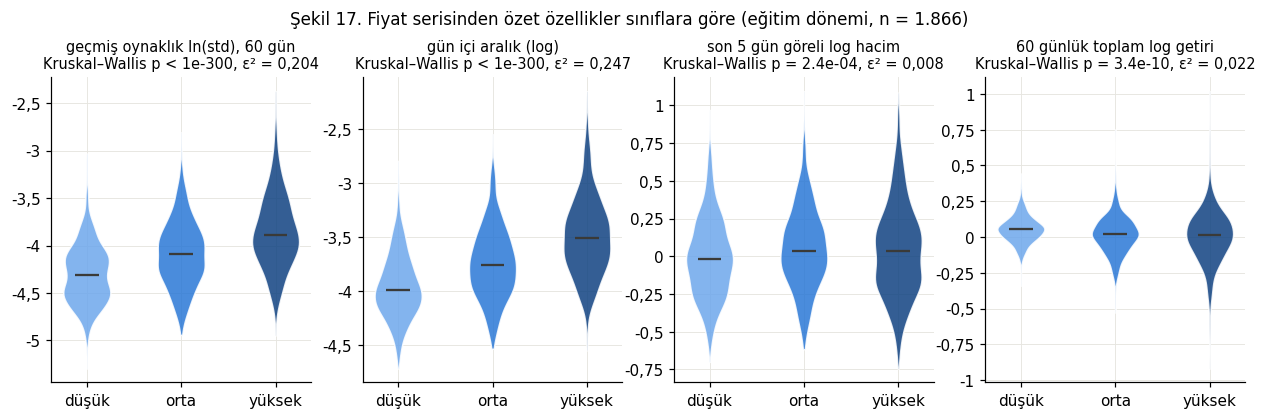

gecmis_oyn_60  Spearman(v) = +0.489 | KW p = 0 | ε² = 0.2044
gecmis_oyn_5   Spearman(v) = +0.411 | KW p = 0 | ε² = 0.1525
aralik_ort     Spearman(v) = +0.538 | KW p = 0 | ε² = 0.2470
hacim_son5     Spearman(v) = +0.066 | KW p = 0.000241 | ε² = 0.0079
getiri_60      Spearman(v) = -0.147 | KW p = 3.41e-10 | ε² = 0.0223
piyasa_once    Spearman(v) = +0.151 | KW p = 5.47e-09 | ε² = 0.0193


In [6]:
oz = ["gecmis_oyn_60", "aralik_ort", "hacim_son5", "getiri_60"]
adlar = {"gecmis_oyn_60": "geçmiş oynaklık ln(std), 60 gün", "aralik_ort": "gün içi aralık (log)",
         "hacim_son5": "son 5 gün göreli log hacim", "getiri_60": "60 günlük toplam log getiri"}
fig, eksen = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, k in zip(eksen, oz):
    vp = ax.violinplot([e.loc[e.sinif == c, k] for c in range(3)], showmedians=True, showextrema=False)
    for b, renk in zip(vp["bodies"], SINIF_RENK):
        b.set_facecolor(renk); b.set_alpha(0.85); b.set_edgecolor("white")
    vp["cmedians"].set_color(KOYU)
    H, p, eps = kw(e, k)
    ax.set_title(f"{adlar[k]}\nKruskal–Wallis {pyaz(p)}, ε² = {tr(eps, 3)}", fontsize=9.5)
    ax.set_xticks([1, 2, 3], SINIF)
    ax.yaxis.set_major_formatter(VIRGUL)
fig.suptitle(f"Şekil 17. Fiyat serisinden özet özellikler sınıflara göre (eğitim dönemi, n = {tr(len(e))})", y=1.05, fontsize=11)
kaydet(fig, "f3_03_fiyat_siniflar")
plt.show()
for k in ["gecmis_oyn_60", "gecmis_oyn_5", "aralik_ort", "hacim_son5", "getiri_60", "piyasa_once"]:
    H, p, eps = kw(e, k)
    print(f"{k:14s} Spearman(v) = {stats.spearmanr(e[k], e.v)[0]:+.3f} | KW p = {p:.3g} | ε² = {eps:.4f}")

**Ne gözlendi:** Fiyat özellikleri sınıfları açıkça ayırıyor: gün içi aralık (ε² = 0,247) ve 60 günlük geçmiş oynaklık (ε² = 0,204) en güçlüleri; medyanlar düşükten yükseğe düzenli artıyor (geçmiş oynaklık −4,31 / −4,09 / −3,89). 60 günlük toplam getiri zayıf ama anlamlı (ε² = 0,022): çağrı öncesinde değer kaybetmiş hisseler daha oynak. Son 5 günün göreli hacmi neredeyse ayırt edici değil (ε² = 0,008).

**Neden önemli:** Oynaklık kalıcıdır: çağrıdan önce oynak olan hisse sonra da oynak olma eğiliminde. Bu, fiyat modalitesinin güçlü bir taban sağladığını ve metnin değerinin bu tabana eklenen bilgiyle ölçülmesi gerektiğini gösterir.

**Sonraki aşamaya etkisi:** Final modelinde fiyat kodlayıcısı ham getiri yanında gün içi aralık kanalını da kullanacak (Faz 2'de 60 × 3 dizinin üçüncü kanalı olarak hazırlandı).

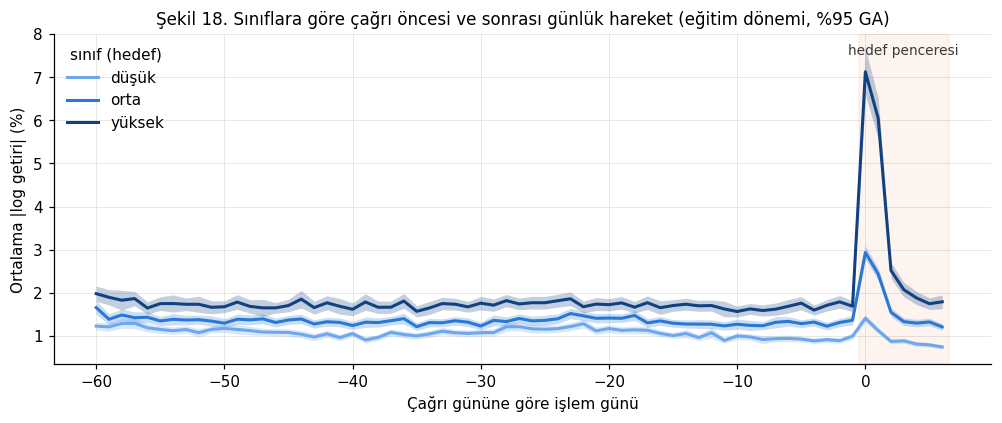

Girdi penceresinde ortalama |getiri| (%): {'düşük': 1.08, 'orta': 1.35, 'yüksek': 1.72}
Hedef penceresinde ortalama |getiri| (%): {'düşük': 0.95, 'orta': 1.73, 'yüksek': 3.31}
Gün 0 / gün +1 ortalama |getiri| (%): {'düşük': (np.float64(1.41), np.float64(1.13)), 'orta': (np.float64(2.94), np.float64(2.44)), 'yüksek': (np.float64(7.13), np.float64(6.05))}


In [7]:
pen = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet", columns=["klasor", "gun", "getiri"])
pen = pen[pen.gun.between(-60, 6) & pen.klasor.isin(e.klasor)].merge(e[["klasor", "sinif"]], on="klasor")
pen["mutlak"] = 100 * pen.getiri.abs()
prof = pen.groupby(["sinif", "gun"]).mutlak.agg(["mean", "std", "count"]).reset_index()
prof["yg"] = 1.96 * prof["std"] / np.sqrt(prof["count"])

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.08)
ax.text(3, 0.97, "hedef penceresi", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color=KOYU)
for c in range(3):
    p_ = prof[prof.sinif == c]
    ax.fill_between(p_.gun, p_["mean"] - p_.yg, p_["mean"] + p_.yg, color=SINIF_RENK[c], alpha=0.25, lw=0)
    ax.plot(p_.gun, p_["mean"], color=SINIF_RENK[c], lw=2, label=SINIF[c])
ax.set_xlabel("Çağrı gününe göre işlem günü")
ax.set_ylabel("Ortalama |log getiri| (%)")
ax.yaxis.set_major_formatter(VIRGUL)
ax.legend(title="sınıf (hedef)", frameon=False, loc="upper left")
ax.set_title(f"Şekil 18. Sınıflara göre çağrı öncesi ve sonrası günlük hareket (eğitim dönemi, %95 GA)")
kaydet(fig, "f3_04_sinif_profili")
plt.show()
ort = pen[pen.gun.between(-60, -1)].groupby("sinif").mutlak.mean()
ort_h = pen[pen.gun.between(0, 6)].groupby("sinif").mutlak.mean()
print("Girdi penceresinde ortalama |getiri| (%):", ort.round(2).rename(index=dict(enumerate(SINIF))).to_dict())
print("Hedef penceresinde ortalama |getiri| (%):", ort_h.round(2).rename(index=dict(enumerate(SINIF))).to_dict())
print("Gün 0 / gün +1 ortalama |getiri| (%):", {SINIF[c]: (round(prof[(prof.sinif == c) & (prof.gun == 0)]["mean"].iloc[0], 2),
      round(prof[(prof.sinif == c) & (prof.gun == 1)]["mean"].iloc[0], 2)) for c in range(3)})

**Ne gözlendi:** Çağrı öncesinde sınıflar arasında kalıcı bir düzey farkı var: girdi penceresinde ortalama günlük mutlak getiri düşük sınıfta %1,08, ortada %1,35, yüksekte %1,72. Çağrı gününde ayrışma çok büyüyor: gün 0 / gün +1 ortalamaları düşük sınıfta %1,41 / %1,13, ortada %2,94 / %2,44, yüksekte %7,13 / %6,05. Hedef penceresi ortalaması 0,95 / 1,73 / 3,31.

**Neden önemli:** Sınıflar arasındaki farkın en büyük kısmı açıklamaya verilen ilk tepkiden (gün 0 ve +1) geliyor; çağrı öncesindeki düzey farkı ise bu tepkinin büyüklüğünü kısmen önceden haber veriyor. Hedef penceresi (gün 0..+6) bu iki günü kapsadığı için hem açılış öncesi hem kapanış sonrası çağrıların tepkisi etikete giriyor.

**Sonraki aşamaya etkisi:** Fiyat modeli düzey farkını (son 60 günün oynaklığı) yakalayabilir; ama tepkinin büyüklüğünü açıklayan içerik metindedir. Bu, iki modaliteyi birlikte kullanmanın gerekçesidir.

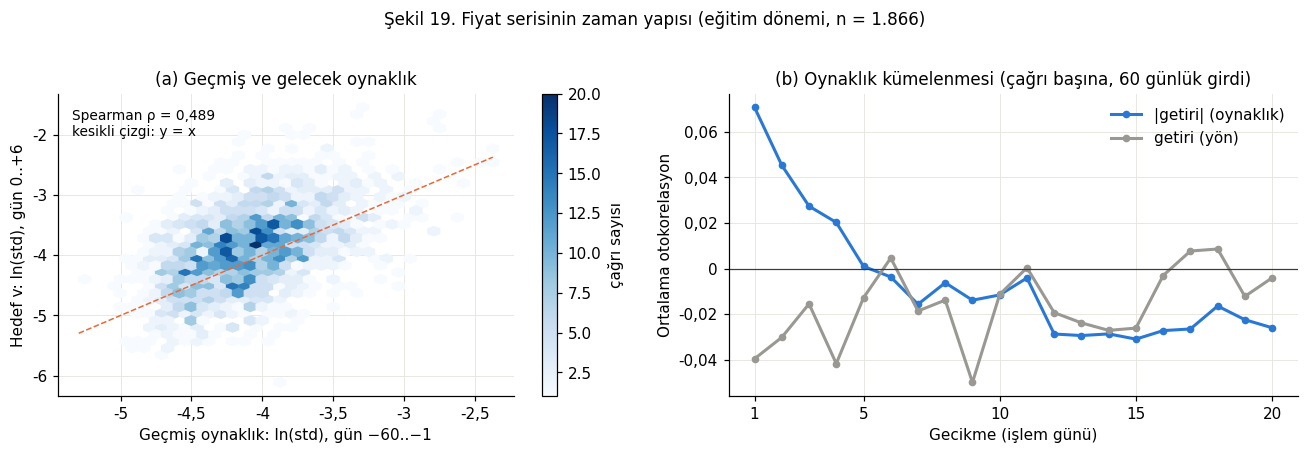

Ortalama otokorelasyon, gecikme 1 / 5 / 10 → |getiri|: [np.float32(0.071), np.float32(0.001), np.float32(-0.012)] | getiri: [np.float32(-0.04), np.float32(-0.013), np.float32(-0.011)]
Hedef, geçmiş oynaklıktan yüksek olan çağrı: %63.3


In [8]:
def oto(seri, gecikme):
    """Her çağrının 60 günlük serisinde verilen gecikmedeki otokorelasyon."""
    a = seri - seri.mean(axis=1, keepdims=True)
    return np.sum(a[:, gecikme:] * a[:, :-gecikme], axis=1) / np.sum(a * a, axis=1)


Xe = X[t.klasor.isin(e.klasor).to_numpy()]
gecikmeler = range(1, 21)
acf_r = [oto(Xe[:, :, 0], g) for g in gecikmeler]
acf_m = [oto(np.abs(Xe[:, :, 0]), g) for g in gecikmeler]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
hb = a1.hexbin(e.gecmis_oyn_60, e.v, gridsize=35, cmap="Blues", mincnt=1)
r_s = stats.spearmanr(e.gecmis_oyn_60, e.v)[0]
a1.plot([e.gecmis_oyn_60.min(), e.gecmis_oyn_60.max()], [e.gecmis_oyn_60.min(), e.gecmis_oyn_60.max()], color=TURUNCU, lw=1, ls="--")
a1.text(0.03, 0.95, f"Spearman ρ = {tr(r_s, 3)}\nkesikli çizgi: y = x", transform=a1.transAxes, va="top", fontsize=9)
a1.set_xlabel("Geçmiş oynaklık: ln(std), gün −60..−1")
a1.set_ylabel("Hedef v: ln(std), gün 0..+6")
a1.set_title("(a) Geçmiş ve gelecek oynaklık")
a1.xaxis.set_major_formatter(VIRGUL); a1.yaxis.set_major_formatter(VIRGUL)
fig.colorbar(hb, ax=a1, label="çağrı sayısı")
a2.plot(gecikmeler, [np.mean(x) for x in acf_m], color=MAVI, marker="o", ms=4, lw=2, label="|getiri| (oynaklık)")
a2.plot(gecikmeler, [np.mean(x) for x in acf_r], color=GRI, marker="o", ms=4, lw=2, label="getiri (yön)")
a2.axhline(0, color=KOYU, lw=0.8)
a2.set_xticks([1, 5, 10, 15, 20])
a2.set_xlabel("Gecikme (işlem günü)")
a2.set_ylabel("Ortalama otokorelasyon")
a2.set_title("(b) Oynaklık kümelenmesi (çağrı başına, 60 günlük girdi)")
a2.yaxis.set_major_formatter(VIRGUL)
a2.legend(frameon=False)
fig.suptitle(f"Şekil 19. Fiyat serisinin zaman yapısı (eğitim dönemi, n = {tr(len(e))})", y=1.02, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_05_zaman_yapisi")
plt.show()
print("Ortalama otokorelasyon, gecikme 1 / 5 / 10 → |getiri|:", [round(np.mean(acf_m[i]), 3) for i in (0, 4, 9)],
      "| getiri:", [round(np.mean(acf_r[i]), 3) for i in (0, 4, 9)])
print(f"Hedef, geçmiş oynaklıktan yüksek olan çağrı: %{100 * (e.v > e.gecmis_oyn_60).mean():.1f}")

**Ne gözlendi:** Geçmiş ve gelecek oynaklık güçlü ilişkili (Spearman ρ = 0,489); çağrıların %63,3'ünde hedef oynaklık, geçmiş 60 günün oynaklığından yüksek (açıklama tepkisi nedeniyle). 60 günlük pencere içinde günlük mutlak getirinin otokorelasyonu ise zayıf ve kısa ömürlü: 1 gün gecikmede 0,071, 5 günde 0,001, 10 günde −0,012; getirinin kendisinde 1 gün gecikmede −0,04.

**Neden önemli:** Oynaklığın kalıcılığı seri içinden çok seriler arası düzey farkında görülüyor: hangi hisse oynaksa çoğunlukla oynak kalıyor, ama tek bir 60 günlük serinin içinde günden güne bağımlılık zayıf. Getirinin yönü neredeyse öngörülemez (otokorelasyon sıfıra yakın); bu da hedefin yön değil büyüklük olmasını destekliyor.

**Sonraki aşamaya etkisi:** Zaman serisi kodlayıcısının asıl katkısı serinin genel düzeyini ve son günlerdeki değişimi özetlemek olacak. Bu nedenle finalde basit bir 1D-CNN ya da küçük bir LSTM yeterli bir başlangıçtır; geçmiş oynaklık tek başına taban model olarak raporlanmalı.

## 4. İstatistiksel dağılım özeti (eğitim dönemi)

Her özellik için sınıf bazında ortalama, medyan, standart sapma ve çeyrekler; Kruskal–Wallis testi (sınıfların
aynı dağılımdan geldiği sıfır hipotezi) ve etki büyüklüğü ε². Ayrıca her özelliğin eğitim dönemi ile 2017–2018
arasındaki medyan farkı (dağılım kayması) verilir.

In [9]:
ozellikler = ["belirsizlik", "olumsuz", "net_ton", "n_kelime", "gecmis_oyn_60", "gecmis_oyn_5", "aralik_ort", "hacim_son5",
              "getiri_60", "piyasa_once", "v"]
satirlar = []
for k in ozellikler:
    H, p, eps = kw(e, k)
    for c in range(3):
        s = e.loc[e.sinif == c, k]
        satirlar.append({"özellik": k, "sınıf": SINIF[c], "ortalama": s.mean(), "medyan": s.median(), "std": s.std(),
                         "Ç1": s.quantile(0.25), "Ç3": s.quantile(0.75), "KW_p": p, "ε²": eps})
istat = pd.DataFrame(satirlar)
istat.to_csv(CIKTI / "f3_istatistik_ozeti.csv", index=False)
print("Sınıf bazında özet istatistikler (ortalama, medyan, std, çeyrekler):")
display(istat.drop(columns=["KW_p", "ε²"]).set_index(["özellik", "sınıf"]).round(3))
print("Medyanlar ve Kruskal–Wallis sonuçları:")
display(istat.pivot(index="özellik", columns="sınıf", values="medyan").loc[ozellikler, SINIF].round(3)
        .join(istat.groupby("özellik")[["KW_p", "ε²"]].first()).round(4))
kayma = d.groupby("donem")[ozellikler].median().T
kayma["fark"] = kayma.iloc[:, 1] - kayma.iloc[:, 0]
print("Dönemlere göre medyanlar (dağılım kayması):")
kayma.round(3)

Sınıf bazında özet istatistikler (ortalama, medyan, std, çeyrekler):


ortalama    medyan       std       Ç1        Ç3
özellik       sınıf                                                  
belirsizlik   düşük      7.936     7.524     4.506    5.083    10.282
              orta       7.679     7.303     4.812    4.959     9.572
              yüksek     7.441     7.100     4.246    4.809     9.596
olumsuz       düşük      7.852     6.890     5.207    5.021     9.659
              orta       7.251     6.616     4.753    4.419     9.285
              yüksek     7.752     7.058     4.784    4.866    10.018
net_ton       düşük      0.344     0.372     0.314    0.181     0.549
              orta       0.368     0.385     0.307    0.189     0.571
              yüksek     0.333     0.355     0.328    0.143     0.548
n_kelime      düşük   1779.103  1506.500  1272.194  842.500  2501.500
              orta    1829.979  1542.000  1331.968  817.000  2471.500
              yüksek  1915.387  1614.000  1393.464  825.500  2779.500
gecmis_oyn_60 düşük     -4.295    -4.310     0.321   -4.527    -4.090
              orta      -4.082    -4.090     0.352   -4.328    -3.859
              yüksek    -3.849    -3.891     0.406   -4.115    -3.600
gecmis_oyn_5  düşük     -4.730    -4.694     0.520   -5.013    -4.388
              orta      -4.420    -4.415     0.561   -4.755    -4.046
              yüksek    -4.156    -4.174     0.594   -4.512    -3.742
aralik_ort    düşük     -3.956    -3.988     0.304   -4.154    -3.768
              orta      -3.741    -3.758     0.336   -3.974    -3.523
              yüksek    -3.488    -3.511     0.377   -3.752    -3.269
hacim_son5    düşük     -0.008    -0.020     0.268   -0.202     0.177
              orta       0.052     0.034     0.271   -0.121     0.213
              yüksek     0.045     0.034     0.312   -0.179     0.224
getiri_60     düşük      0.054     0.055     0.098   -0.004     0.110
              orta       0.015     0.019     0.136   -0.065     0.097
              yüksek     0.005     0.011     0.208   -0.102     0.116
piyasa_once   düşük     -5.049    -5.076     0.304   -5.241    -4.910
              orta      -4.956    -5.046     0.363   -5.168    -4.788
              yüksek    -4.918    -5.037     0.404   -5.168    -4.613
v             düşük     -4.577    -4.516     0.333   -4.765    -4.309
              orta      -3.876    -3.874     0.155   -4.016    -3.740
              yüksek    -3.166    -3.237     0.369   -3.458    -2.959

Medyanlar ve Kruskal–Wallis sonuçları:


,düşük,orta,yüksek,KW_p,ε²
özellik,,,,,
belirsizlik,7.524,7.303,7.100,0.1184,0.0012
olumsuz,6.890,6.616,7.058,0.0632,0.0019
net_ton,0.372,0.385,0.355,0.1695,0.0008
n_kelime,1506.500,1542.000,1614.000,0.4289,-0.0002
gecmis_oyn_60,-4.310,-4.090,-3.891,0.0000,0.2044
gecmis_oyn_5,-4.694,-4.415,-4.174,0.0000,0.1525
aralik_ort,-3.988,-3.758,-3.511,0.0000,0.2470
hacim_son5,-0.020,0.034,0.034,0.0002,0.0079
getiri_60,0.055,0.019,0.011,0.0000,0.0223


Dönemlere göre medyanlar (dağılım kayması):


donem,eğitim (≤2016),sonrası (2017–2018),fark
belirsizlik,7.299,7.741,0.442
olumsuz,6.879,7.137,0.258
net_ton,0.371,0.398,0.026
n_kelime,1558.000,2816.000,1258.000
gecmis_oyn_60,-4.097,-4.209,-0.113
gecmis_oyn_5,-4.435,-4.563,-0.128
aralik_ort,-3.756,-3.814,-0.057
hacim_son5,0.014,0.008,-0.005
getiri_60,0.031,0.038,0.007
piyasa_once,-5.058,-5.432,-0.374


**Ne gözlendi:** Fiyat özelliklerinde sınıflar arası fark büyük ve anlamlı: gün içi aralık ε² ≈ 0,25, geçmiş
oynaklık ε² ≈ 0,20; düşük sınıftan yükseğe medyanlar düzenli artıyor. Sözlük özelliklerinde ε² sıfıra yakın.
Piyasa geneli oynaklık (`piyasa_once`) küçük ama anlamlı bir fark gösteriyor. Dönemler arası kayma: 2017–2018'de
piyasa oynaklığı (medyan −5,058 → −5,432) ve hedef (−3,874 → −3,965) daha düşük; metinler ise belirgin biçimde daha uzun
(medyan 1.558 → 2.816 kelime).

**Neden önemli:** Fiyat geçmişi tek başına güçlü bir taban (baseline) sunuyor; metnin değeri, bu tabanın
üzerine ne eklediğiyle ölçülmeli. Dönemler arası kayma, zaman bölmesinde test dağılımının eğitimden farklı
olacağını gösteriyor. Metin uzunluğundaki büyük kayma, uzunluğa duyarlı gösterimlerin (ör. normalize edilmemiş kelime
sayıları) zaman bölmesinde yanıltıcı olabileceğini gösteriyor.

**Sonraki aşamaya etkisi:** Final modelinde geçmiş oynaklık mutlaka bir taban model olarak raporlanmalı (literatürdeki
"geçmiş oynaklık" tabanı gibi). Zaman bölmesinde sınıf ağırlıkları ve makro-F1 kullanılmalı.

## 5. Modaliteler arası ilişkiler

### 5.1 Metin benzerliği: benzer metinli başka şirketlerin oynaklığı

**Yöntem:** Eğitim dönemindeki metinler TF-IDF ile vektörleştirilir (yalnız eğitim döneminden öğrenilen sözlük;
durak kelimeler hariç, en az 5 çağrıda geçen kelimeler). Her çağrı için kosinüs benzerliğine göre en benzer 10 çağrı
bulunur. **Aynı şirketin çağrıları dışarıda bırakılır** ve **her komşu şirketten yalnız en benzer tek çağrı** alınır;
böylece 10 komşu 10 farklı şirketten gelir, ne kendi şirketinin kimliği ne de tek bir başka şirket ölçüme hâkim olur.
`komsu_v` = bu 10 komşunun hedef oynaklık ortalaması. Model eğitimi yoktur; bu bir benzerlik analizidir.

In [10]:
metinler = [" ".join(s) for s in t.set_index("klasor").loc[e.klasor, "cumleler_temiz"]]
K = 10
komsu, B, tf, A = metin_komsulari(metinler, e.ticker, K=K)       # TF-IDF yalnız bu (eğitim dönemi) metinlerden öğrenilir
assert all(len(set(e.ticker.to_numpy()[k])) == K for k in komsu), "komşular 10 farklı şirketten olmalı"
assert not (e.ticker.to_numpy()[komsu] == e.ticker.to_numpy()[:, None]).any(), "kendi şirketi komşu olamaz"
e["komsu_v"] = e.v.to_numpy()[komsu].mean(axis=1)
e["komsu_gecmis"] = e.gecmis_oyn_60.to_numpy()[komsu].mean(axis=1)
e["komsu_ayni_sektor"] = (e.bolum.to_numpy()[komsu] == e.bolum.to_numpy()[:, None]).mean(axis=1)
print(f"TF-IDF sözlüğü: {A.shape[1]:,} kelime | komşu sayısı: {K} | komşuların aynı sektörden olma payı: "
      f"%{100 * e.komsu_ayni_sektor[e.bolum != 'bilinmiyor'].mean():.1f}")
bolum_payi = e.bolum.value_counts(normalize=True)
print(f"Karşılaştırma: rastgele iki çağrının aynı sektörden olma olasılığı ≈ %{100 * (bolum_payi ** 2).sum():.1f}")
print(f"Spearman(komsu_v, v) = {stats.spearmanr(e.komsu_v, e.v)[0]:.3f} | Spearman(komsu_v, geçmiş oynaklık) = "
      f"{stats.spearmanr(e.komsu_v, e.gecmis_oyn_60)[0]:.3f}")

TF-IDF sözlüğü: 9,157 kelime | komşu sayısı: 10 | komşuların aynı sektörden olma payı: %44.6
Karşılaştırma: rastgele iki çağrının aynı sektörden olma olasılığı ≈ %19.7
Spearman(komsu_v, v) = 0.263 | Spearman(komsu_v, geçmiş oynaklık) = 0.220


### 5.2 Korelasyon haritası
Metin, fiyat ve piyasa özelliklerinin hedefle ve birbirleriyle sıra (Spearman) korelasyonları.

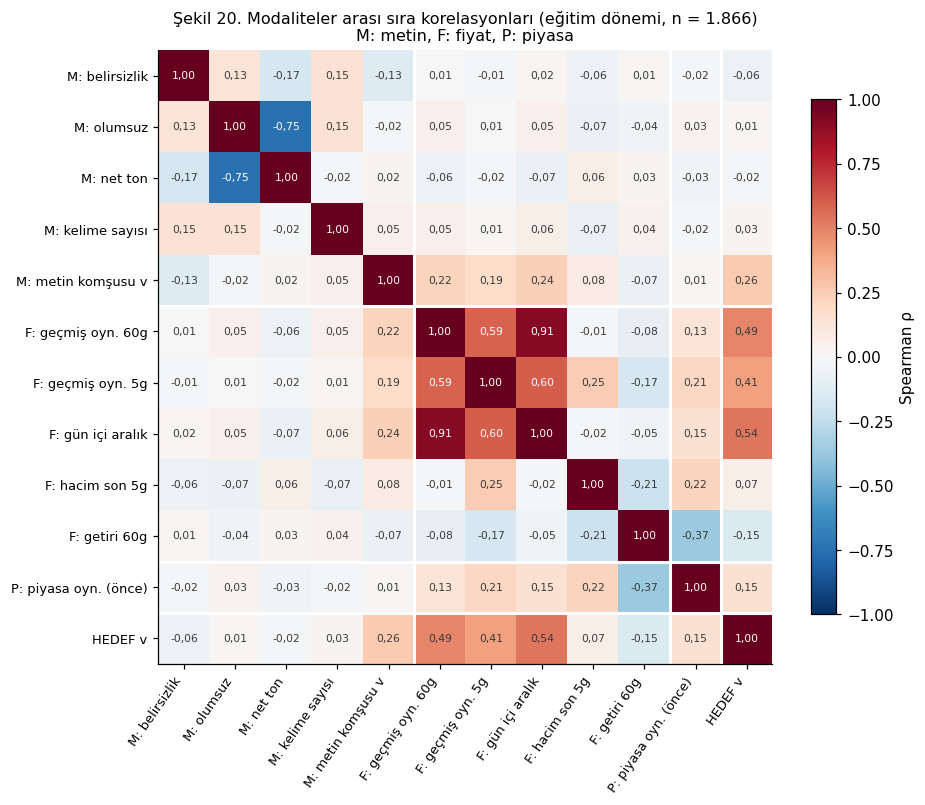

Hedefle korelasyonlar: {'getiri_60': -0.147, 'belirsizlik': -0.061, 'net_ton': -0.022, 'olumsuz': 0.01, 'n_kelime': 0.03, 'hacim_son5': 0.066, 'piyasa_once': 0.151, 'komsu_v': 0.263, 'gecmis_oyn_5': 0.411, 'gecmis_oyn_60': 0.489, 'aralik_ort': 0.538}
Metin komşusu v ile fiyat özellikleri: {'gecmis_oyn_60': 0.22, 'aralik_ort': 0.24, 'hacim_son5': 0.079}


In [11]:
kol = ["belirsizlik", "olumsuz", "net_ton", "n_kelime", "komsu_v", "gecmis_oyn_60", "gecmis_oyn_5", "aralik_ort",
       "hacim_son5", "getiri_60", "piyasa_once", "v"]
etiket_ad = {"belirsizlik": "M: belirsizlik", "olumsuz": "M: olumsuz", "net_ton": "M: net ton", "n_kelime": "M: kelime sayısı",
             "komsu_v": "M: metin komşusu v", "gecmis_oyn_60": "F: geçmiş oyn. 60g", "gecmis_oyn_5": "F: geçmiş oyn. 5g",
             "aralik_ort": "F: gün içi aralık", "hacim_son5": "F: hacim son 5g", "getiri_60": "F: getiri 60g",
             "piyasa_once": "P: piyasa oyn. (önce)", "v": "HEDEF v"}
C = e[kol].corr(method="spearman")
C.to_csv(CIKTI / "f3_korelasyon.csv")
fig, ax = plt.subplots(figsize=(9, 7.6))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kol)), [etiket_ad[k] for k in kol], rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(len(kol)), [etiket_ad[k] for k in kol], fontsize=8.5)
for i in range(len(kol)):
    for j in range(len(kol)):
        ax.text(j, i, tr(C.values[i, j], 2), ha="center", va="center", fontsize=7, color="white" if abs(C.values[i, j]) > 0.55 else KOYU)
ax.grid(False)
for k in (4.5, 9.5, 10.5):
    ax.axhline(k, color="white", lw=2); ax.axvline(k, color="white", lw=2)
fig.colorbar(im, ax=ax, label="Spearman ρ", shrink=0.8)
ax.set_title(f"Şekil 20. Modaliteler arası sıra korelasyonları (eğitim dönemi, n = {tr(len(e))})\nM: metin, F: fiyat, P: piyasa", fontsize=10.5)
kaydet(fig, "f3_06_korelasyon")
plt.show()
print("Hedefle korelasyonlar:", C["v"].drop("v").round(3).sort_values().to_dict())
print("Metin komşusu v ile fiyat özellikleri:", C.loc["komsu_v", ["gecmis_oyn_60", "aralik_ort", "hacim_son5"]].round(3).to_dict())

**Ne gözlendi:** TF-IDF sözlüğü yalnız eğitim döneminden öğrenildi (9.157 kelime). Metin komşuları %44,6 oranında aynı sektörden; rastgele iki çağrıda bu olasılık yaklaşık %19,7. Metin komşusu v hedefle ρ = 0,263 korelasyonlu; fiyat özellikleriyle korelasyonu daha düşük (geçmiş oynaklık 0,22, aralık 0,24). Sözlük özellikleri birbirleriyle (olumsuz – net ton −0,75) ilişkili ama fiyatla ve hedefle neredeyse ilişkisiz. Fiyat özellikleri birbirine çok yakın (geçmiş oynaklık – aralık 0,91).

**Neden önemli:** Metin komşusu sinyali, model kurmadan elde edilmiş bir "metin → oynaklık" bağlantısı: içeriği benzeyen başka şirketlerin oynaklığı bu çağrınınkini kısmen anlatıyor. Fiyatla korelasyonunun orta düzeyde kalması, iki modalitenin aynı bilgiyi tekrar etmediğini düşündürüyor; bunu Bölüm 5.3'teki kısmi korelasyon doğrudan test ediyor. Geçmiş oynaklık ile aralığın 0,91 korelasyonu, fiyat kanallarının bir kısmının birbirini tekrarladığını gösteriyor.

**Sonraki aşamaya etkisi:** Metnin katkısı büyük ölçüde sektör/iş modeli benzerliğinden geliyor olabilir (komşuların yarıya yakını aynı sektörden); finalde sektör bilgisi ayrıca verilerek metnin bunun ötesindeki katkısı ölçülmeli.

### 5.3 Tamamlayıcılık: metin, fiyat geçmişinin üzerine bilgi ekliyor mu?

İki yöntem: (a) **kısmi sıra korelasyonu**: bir özelliğin hedefle ilişkisi, diğer modalitenin etkisi çıkarıldıktan
sonra ölçülür (değişkenler sıraya çevrilir, kontrol değişkenlerine doğrusal regresyonla arındırılır, artıkların
korelasyonu alınır). Güven aralıkları **şirket düzeyinde** önyükleme (bootstrap, 1.000 tekrar) ile: aynı şirketin
çağrıları birlikte örneklenir. (b) **3 × 3 tablo**: geçmiş oynaklık ve metin komşusu sinyalinin terciline göre
yüksek sınıf payı.

In [12]:
ornekler = sirket_ornekleri(e.ticker, B=1000, tohum=0)   # şirket düzeyinde önyükleme

testler = [
    ("metin komşusu v → v", "komsu_v", []),
    ("metin komşusu v → v | geçmiş oyn. + aralık", "komsu_v", ["gecmis_oyn_60", "aralik_ort"]),
    ("metin komşusu v → v | geçmiş oyn. + aralık + piyasa", "komsu_v", ["gecmis_oyn_60", "aralik_ort", "piyasa_once"]),
    ("geçmiş oyn. → v | metin komşusu v", "gecmis_oyn_60", ["komsu_v"]),
    ("gün içi aralık → v | metin komşusu v", "aralik_ort", ["komsu_v"]),
    ("belirsizlik (LM) → v | geçmiş oyn. + aralık", "belirsizlik", ["gecmis_oyn_60", "aralik_ort"]),
    ("piyasa oyn. (önce) → v | geçmiş oyn. + aralık", "piyasa_once", ["gecmis_oyn_60", "aralik_ort"]),
]
sonuc = []
for ad, x, kontrol in testler:
    nokta = kismi(e, x, "v", kontrol)
    dagilim = [kismi(e.iloc[s], x, "v", kontrol) for s in ornekler]
    alt, ust_ = np.percentile(dagilim, [2.5, 97.5])
    sonuc.append({"ilişki": ad, "kısmi ρ": nokta, "%95 GA alt": alt, "%95 GA üst": ust_, "GA sıfırı içeriyor mu": alt <= 0 <= ust_})
kismi_tablo = pd.DataFrame(sonuc)
kismi_tablo.to_csv(CIKTI / "f3_kismi_korelasyon.csv", index=False)
kismi_tablo.round(3)

,ilişki,kısmi ρ,%95 GA alt,%95 GA üst,GA sıfırı içeriyor mu
0,metin komşusu v → v,0.263,0.211,0.308,False
1,metin komşusu v → v | geçmiş oyn. + aralık,0.164,0.120,0.209,False
2,metin komşusu v → v | geçmiş oyn. + aralık + p...,0.167,0.123,0.212,False
3,geçmiş oyn. → v | metin komşusu v,0.458,0.421,0.493,False
4,gün içi aralık → v | metin komşusu v,0.507,0.469,0.542,False
5,belirsizlik (LM) → v | geçmiş oyn. + aralık,-0.087,-0.133,-0.043,False
6,piyasa oyn. (önce) → v | geçmiş oyn. + aralık,0.084,0.034,0.125,False


**Ne gözlendi:** Metin komşusu v'nin hedefle kısmi korelasyonu, geçmiş oynaklık ve aralık kontrol edildikten sonra 0,164 (%95 GA 0,120–0,209); piyasa oynaklığı da eklenince 0,167 (0,123–0,212). Ters yönde, fiyatın metin üzerine katkısı daha büyük: geçmiş oynaklık 0,458, aralık 0,507. LM belirsizlik oranı fiyat kontrol edilince küçük ve negatif (−0,087; −0,133 ile −0,043). Piyasa oynaklığı fiyatın üzerine küçük bir katkı veriyor (0,084; 0,034–0,125). Hiçbir güven aralığı sıfırı içermiyor.

**Neden önemli:** Bu, iki modalitenin birbirini tamamladığının model kurulmadan elde edilen sayısal kanıtı: metin, fiyat geçmişinin açıklayamadığı oynaklık farkını kısmen açıklıyor ve bu etki piyasa havasıyla açıklanamıyor. Güven aralıkları şirket düzeyinde örneklendiği için aynı şirketin çağrıları arasındaki bağımlılık hesaba katıldı. Belirsizlik oranının beklenenin tersine negatif çıkması, sözlük sayımının bu veride oynaklığın iyi bir göstergesi olmadığını bir kez daha gösteriyor.

**Sonraki aşamaya etkisi:** Final modelinde ablasyon (yalnız fiyat, yalnız metin, ikisi birlikte) yapıldığında metnin fiyat üzerine katkısının pozitif olması bekleniyor; bu bölüm o deneyin hipotezini veriyle destekliyor.

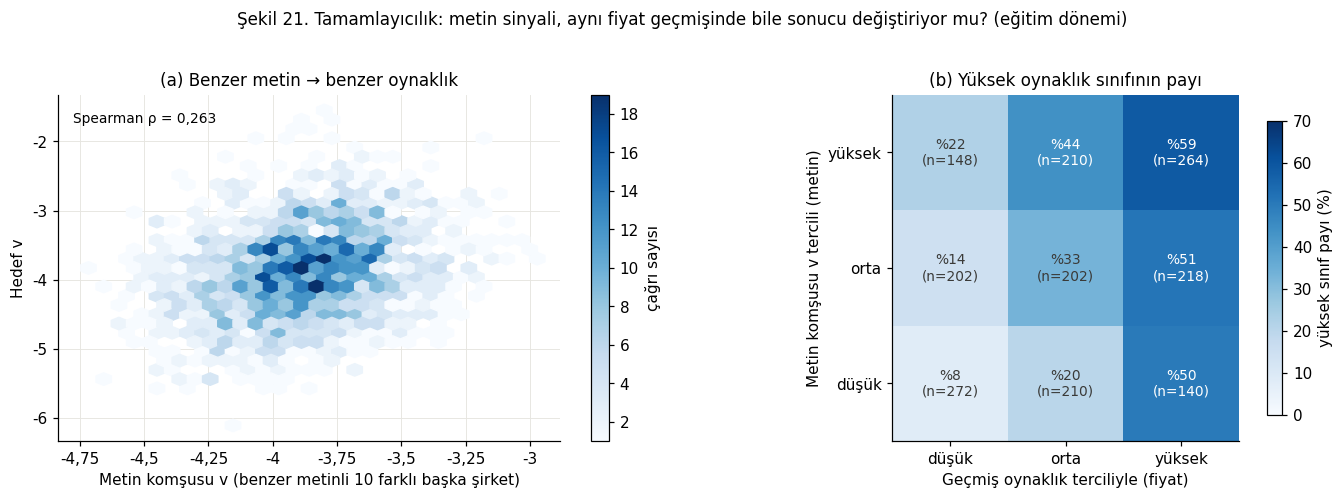

Yüksek sınıf payı (%), satır: metin tercili, sütun: geçmiş oynaklık tercili


gecmis_t,düşük,orta,yüksek
komsu_t,,,
düşük,8.1,20.0,50.0
orta,14.4,33.2,51.4
yüksek,22.3,43.8,58.7


In [13]:
e["gecmis_t"] = pd.qcut(e.gecmis_oyn_60, 3, labels=["düşük", "orta", "yüksek"])
e["komsu_t"] = pd.qcut(e.komsu_v, 3, labels=["düşük", "orta", "yüksek"])
pay = e.assign(yuksek=(e.sinif == 2)).pivot_table(index="komsu_t", columns="gecmis_t", values="yuksek", aggfunc="mean", observed=False) * 100
say = e.pivot_table(index="komsu_t", columns="gecmis_t", values="v", aggfunc="size", observed=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
hb = a1.hexbin(e.komsu_v, e.v, gridsize=30, cmap="Blues", mincnt=1)
a1.text(0.03, 0.95, f"Spearman ρ = {tr(stats.spearmanr(e.komsu_v, e.v)[0], 3)}", transform=a1.transAxes, va="top", fontsize=9)
a1.set_xlabel("Metin komşusu v (benzer metinli 10 farklı başka şirket)")
a1.set_ylabel("Hedef v")
a1.set_title("(a) Benzer metin → benzer oynaklık")
a1.xaxis.set_major_formatter(VIRGUL); a1.yaxis.set_major_formatter(VIRGUL)
fig.colorbar(hb, ax=a1, label="çağrı sayısı")
im = a2.imshow(pay.values, cmap="Blues", vmin=0, vmax=70, origin="lower")
for i in range(3):
    for j in range(3):
        a2.text(j, i, f"%{tr(pay.values[i, j], 0)}\n(n={say.values[i, j]})", ha="center", va="center", fontsize=9,
                color="white" if pay.values[i, j] > 40 else KOYU)
a2.set_xticks(range(3), pay.columns); a2.set_yticks(range(3), pay.index)
a2.set_xlabel("Geçmiş oynaklık terciliyle (fiyat)")
a2.set_ylabel("Metin komşusu v tercili (metin)")
a2.grid(False)
a2.set_title("(b) Yüksek oynaklık sınıfının payı")
fig.colorbar(im, ax=a2, label="yüksek sınıf payı (%)", shrink=0.85)
fig.suptitle("Şekil 21. Tamamlayıcılık: metin sinyali, aynı fiyat geçmişinde bile sonucu değiştiriyor mu? (eğitim dönemi)", y=1.02, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_07_tamamlayicilik")
plt.show()
print("Yüksek sınıf payı (%), satır: metin tercili, sütun: geçmiş oynaklık tercili")
pay.round(1)

**Ne gözlendi:** Aynı geçmiş oynaklık tercili içinde metin sinyali yükseldikçe yüksek oynaklık sınıfının payı artıyor: düşük geçmiş oynaklıkta %8,1 → %14,4 → %22,3; orta tercilde %20,0 → %33,2 → %43,8; yüksek tercilde %50,0 → %51,4 → %58,7. En yüksek pay iki modalitenin birlikte yüksek olduğu hücrede (%58,7), en düşük pay ikisinin birlikte düşük olduğu hücrede (%8,1).

**Neden önemli:** Tablo kısmi korelasyonun görsel karşılığı: fiyat geçmişi aynıyken metin sonucu değiştiriyor. Etki, fiyatın henüz alarm vermediği düşük ve orta tercillerde daha büyük (yaklaşık 14 ve 24 yüzde puan); fiyat zaten yüksekken metnin ek katkısı küçülüyor (yaklaşık 9 puan).

**Sonraki aşamaya etkisi:** Füzyonun en çok, fiyat geçmişi sakin olan çağrılarda işe yaraması bekleniyor; final değerlendirmesinde sonuçları geçmiş oynaklık tercillerine göre ayrı raporlamak bu hipotezi test eder.

### 5.4 Zamansal eşleşme ve piyasa geneli oynaklık (karıştırıcı etki)

Bir çağrının oynaklığı yalnız şirkete değil, o haftaki piyasa havasına da bağlıdır. Piyasa geneli oynaklık hem
metni (yöneticilerin anlattığı ortam) hem fiyatı etkileyebileceği için karıştırıcı (confounder) olabilir. SPY (S&P 500
fonu) gerçekleşen oynaklığı ile çağrıların hedef oynaklığı aynı zaman ekseninde incelenir. Burada tüm dönem
gösterilir, çünkü amaç model seçimi değil zaman yapısını görmek.

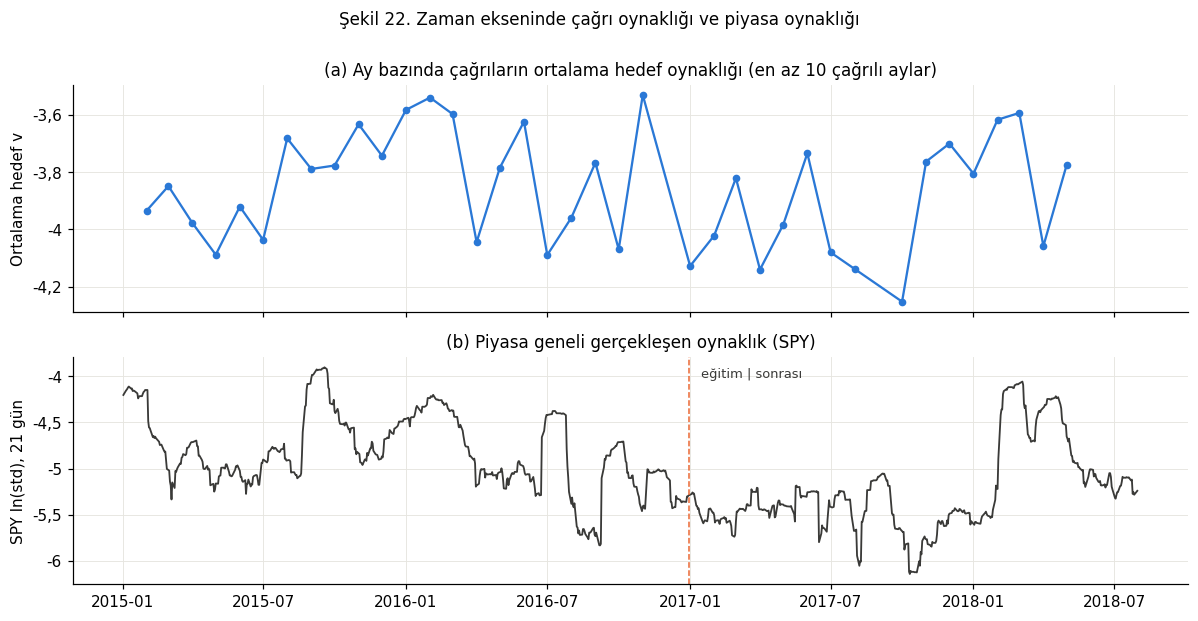

Aylık ortalama v ile aylık piyasa oynaklığı (hedef penceresi) Spearman: 0.529 (ay sayısı 38)
Çağrı düzeyinde: Spearman(v, piyasa_hedef) = 0.193, Spearman(v, piyasa_once) = 0.135
Çağrıların aylara dağılımı (en yoğun 6 ay): {'2017-02': 250, '2016-05': 219, '2016-08': 219, '2016-10': 169, '2016-02': 160, '2016-07': 149}


In [14]:
d["ay"] = d.t0.dt.to_period("M").dt.to_timestamp()
aylik = d.groupby("ay").agg(v=("v", "mean"), n=("v", "size"), piyasa=("piyasa_hedef", "mean"))
aylik = aylik[aylik.n >= 10]
spy_s = spy.sort_values("date").set_index("date")
spy_r = np.log(spy_s["adj close"]).diff()
spy_oyn = np.log(spy_r.rolling(21).std()).loc["2015-01-01":"2018-07-31"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
a1.plot(aylik.index, aylik.v, color=MAVI, marker="o", ms=4, lw=1.5)
a1.set_ylabel("Ortalama hedef v")
a1.set_title("(a) Ay bazında çağrıların ortalama hedef oynaklığı (en az 10 çağrılı aylar)")
a1.yaxis.set_major_formatter(VIRGUL)
a2.plot(spy_oyn.index, spy_oyn.values, color=KOYU, lw=1.2)
a2.axvline(pd.Timestamp("2016-12-31"), color=TURUNCU, ls="--", lw=1)
a2.text(pd.Timestamp("2017-01-15"), spy_oyn.max(), "eğitim | sonrası", fontsize=8.5, va="top", color=KOYU)
a2.set_ylabel("SPY ln(std), 21 gün")
a2.set_title("(b) Piyasa geneli gerçekleşen oynaklık (SPY)")
a2.yaxis.set_major_formatter(VIRGUL)
fig.suptitle("Şekil 22. Zaman ekseninde çağrı oynaklığı ve piyasa oynaklığı", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_08_zaman_piyasa")
plt.show()
print(f"Aylık ortalama v ile aylık piyasa oynaklığı (hedef penceresi) Spearman: {stats.spearmanr(aylik.v, aylik.piyasa)[0]:.3f} (ay sayısı {len(aylik)})")
print(f"Çağrı düzeyinde: Spearman(v, piyasa_hedef) = {stats.spearmanr(d.v, d.piyasa_hedef)[0]:.3f}, "
      f"Spearman(v, piyasa_once) = {stats.spearmanr(d.v, d.piyasa_once)[0]:.3f}")
print("Çağrıların aylara dağılımı (en yoğun 6 ay):", d.ay.dt.strftime("%Y-%m").value_counts().head(6).to_dict())

**Ne gözlendi:** Aylık ortalama hedef oynaklık ile aynı ayın piyasa oynaklığı belirgin biçimde birlikte hareket ediyor (38 ayda Spearman 0,529). Çağrı düzeyinde ilişki daha zayıf: hedefle eşzamanlı piyasa oynaklığı 0,193, çağrıdan önceki piyasa oynaklığı 0,135. Çağrılar kazanç sezonlarında yığılıyor (en yoğun aylar 2017-02: 250; 2016-05 ve 2016-08: 219'ar çağrı). 2017'de piyasa belirgin biçimde sakin.

**Neden önemli:** Hedefin bir kısmı şirkete değil o haftanın piyasa havasına ait; aynı kazanç sezonundaki çağrılar ortak bir piyasa şokunu paylaşır. Bu hem karıştırıcı bir etki (piyasa hem metni hem fiyatı etkileyebilir) hem de bölme için bir uyarı: aynı haftadaki çağrıların biri eğitimde biri testteyse ortak şok bilgi taşıyabilir.

**Sonraki aşamaya etkisi:** Modele yalnız çağrıdan önce bilinen piyasa oynaklığı (`piyasa_once`) girebilir; eşzamanlı piyasa oynaklığı sızıntı olur. Faz 4'te zaman bölmesinde eğitim ile test arasına boşluk (ambargo) konacak; dönemler arası piyasa farkı test skorlarını etkileyebilir.

### 5.5 Aynı örnek üzerinde iki modalite: benzer fiyat geçmişi, farklı metin sinyali

Seçim kuralı (elle seçim yok): geçmiş oynaklığı orta tercilde olan ve en az 500 kelimelik eğitim çağrıları arasından
metin komşusu sinyali en yüksek ve en düşük olan iki çağrı.

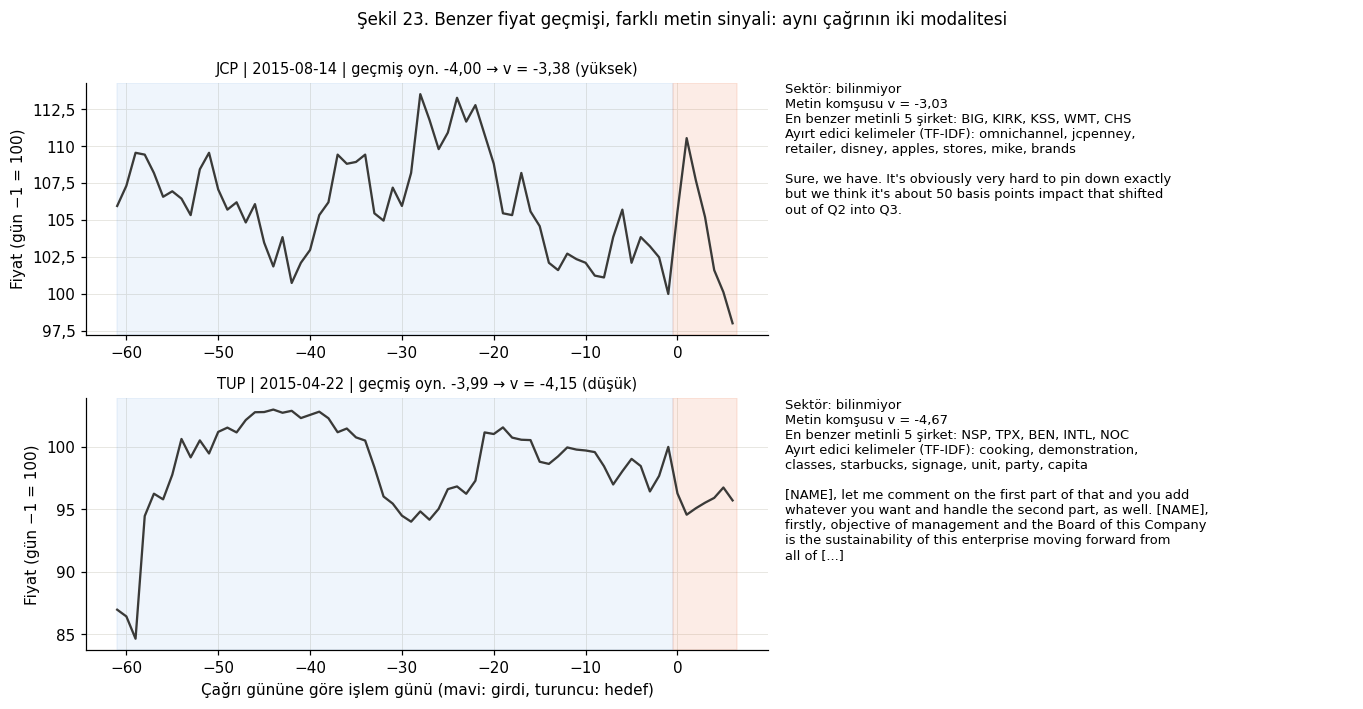

In [15]:
aday = e[(e.gecmis_t == "orta") & (e.n_kelime >= 500)]
secim = [aday.komsu_v.idxmax(), aday.komsu_v.idxmin()]
pen_t = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet", columns=["klasor", "gun", "adj close"])
cum_t = t.set_index("klasor").cumleler_temiz
kelime_ad = np.array(tf.get_feature_names_out())
fig, eksen = plt.subplots(2, 2, figsize=(12.5, 6.4), gridspec_kw={"width_ratios": [1.2, 1]})
for (sol, sag), i in zip(eksen, secim):
    r = e.loc[i]
    p_ = pen_t[(pen_t.klasor == r.klasor) & pen_t.gun.between(-61, 6)].set_index("gun")["adj close"]
    p_ = 100 * p_ / p_.loc[-1]
    sol.axvspan(-61, -0.5, color=MAVI, alpha=0.07); sol.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.12)
    sol.plot(p_.index, p_.values, color=KOYU, lw=1.5)
    sol.set_title(f"{r.ticker} | {r.tarih.date()} | geçmiş oyn. {tr(r.gecmis_oyn_60, 2)} → v = {tr(r.v, 2)} ({SINIF[r.sinif]})", fontsize=9.5)
    sol.set_ylabel("Fiyat (gün −1 = 100)")
    sol.yaxis.set_major_formatter(VIRGUL)
    komsular = e.ticker.to_numpy()[komsu[i]][:5]
    sag.axis("off")
    satir_ = A[i].toarray().ravel()
    ayirt = ", ".join(kelime_ad[np.argsort(-satir_)[:8]])
    sag.text(0, 1, f"Sektör: {r.bolum}\nMetin komşusu v = {tr(r.komsu_v, 2)}\nEn benzer metinli 5 şirket: {', '.join(komsular)}\n"
             + textwrap.fill(f"Ayırt edici kelimeler (TF-IDF): {ayirt}", 62) + "\n\n"
             + textwrap.fill(textwrap.shorten(" ".join(cum_t[r.klasor][:2]), 260), 62), va="top", fontsize=8.5)
eksen[-1][0].set_xlabel("Çağrı gününe göre işlem günü (mavi: girdi, turuncu: hedef)")
fig.suptitle("Şekil 23. Benzer fiyat geçmişi, farklı metin sinyali: aynı çağrının iki modalitesi", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_09_eslesik_ornek")
plt.show()

**Ne gözlendi:** Geçmiş oynaklıkları neredeyse aynı (−4,00 ve −3,99) iki çağrı. JCP'nin metin komşuları perakendeciler (BIG, KIRK, KSS, WMT, CHS), ayırt edici kelimeleri omnichannel, retailer, stores; metin komşusu v = −3,03 ve sonuç yüksek oynaklık (v = −3,38). TUP'un komşuları farklı sektörlerden (NSP, TPX, BEN, INTL, NOC), metin komşusu v = −4,67 ve sonuç düşük oynaklık (v = −4,15).

**Neden önemli:** Aynı fiyat geçmişine sahip iki çağrıyı yalnız fiyatla ayırmak mümkün değil; metin, şirketin hangi tür şirketlere benzediğini ve dolayısıyla tepkinin büyüklüğünü taşıyor. Tek bir örnek kanıt değildir; kanıt Bölüm 5.3'teki kısmi korelasyon ve 3 × 3 tablodur, bu şekil onların somut bir örneği. Not: JCP'nin kelimelerinde bir kişi adı (mike) maskelenmemiş; MAEC maskelemesinin tam olmadığına bir örnek daha.

**Sonraki aşamaya etkisi:** Final modelinde metin gösteriminin sektör ve iş modeli bilgisini koruması önemli; yalnız ton ölçen gösterimler bu farkı yakalayamaz.

## 6. Aykırı durum ve örnek olay analizi

Dört tür çağrı karşılaştırılır (hepsi koddaki kurallarla seçilir, eğitim dönemi):
- **normal:** hedef oynaklığı ve geçmiş oynaklığı medyana en yakın çağrı,
- **uç:** en yüksek hedef oynaklıklı çağrı,
- **çelişkili:** geçmiş oynaklığa göre beklenenden en çok sapan çağrı (v'nin geçmiş oynaklığa doğrusal regresyonundaki en büyük pozitif artık),
- **düşük kaliteli metin:** temizlikten sonra kalan en kısa metinli çağrı.

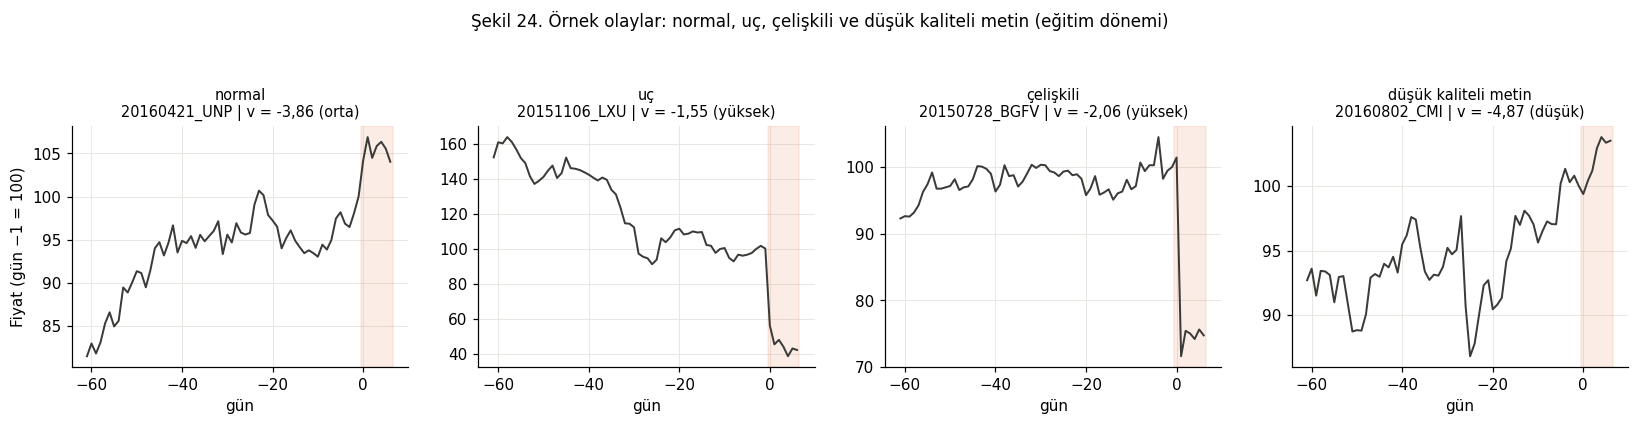

,ticker,bolum,v,gecmis_oyn_60,aralik_ort,komsu_v,belirsizlik,net_ton,n_kelime,artik
normal,UNP,"Ulaştırma, iletişim, altyapı",-3.864165,-4.092299,-3.658567,-4.206906,6.775068,0.138462,2214,0.022404
uç,LXU,İmalat,-1.550753,-3.283373,-3.050079,-3.815468,4.983389,0.809524,602,1.690935
çelişkili,BGFV,bilinmiyor,-2.064103,-4.122235,-3.605788,-3.359274,11.312993,-0.188406,2917,1.84633
düşük kaliteli metin,CMI,İmalat,-4.871628,-3.989803,-3.875838,-4.167558,0.0,0.0,21,-1.06677


Hedef penceresindeki günlük log getiriler (%):


gun,0,1,2,3,4,5,6
klasor,,,,,,,
20150728_BGFV,1.42,-34.84,5.19,-0.54,-1.10,1.91,-1.18
20151106_LXU,-58.02,-21.27,5.56,-8.61,-13.19,10.92,-2.03
20160421_UNP,4.06,2.61,-2.28,1.30,0.46,-0.74,-1.46
20160802_CMI,-0.63,1.02,0.79,1.68,0.85,-0.42,0.15


Eğitim dönemi içindeki yüzdelik sıra (0 = en düşük, 100 = en yüksek):


,v,gecmis_oyn_60,aralik_ort,komsu_v,belirsizlik,olumsuz,net_ton,n_kelime
normal,50,51,60,12,44,90,22,67
uç,100,96,95,58,26,13,95,17
çelişkili,100,47,65,97,84,93,6,80
düşük kaliteli metin,6,61,39,15,5,4,14,0


[normal] olumsuz/belirsiz kelimesi en yoğun cümleler: We are coming off of unusually high negative mix challenges. | And you can make an argument either way that it strengthens a bit or that it might decline a bit.
[uç] olumsuz/belirsiz kelimesi en yoğun cümleler: As [NAME] and I both indicated, we look to improve our capital structure cost as soon as we possibly can and we will focus on that. | As you probably know, we've worked with CS on multiple occasions over the last two years, and so we did work with CS and there was a process that was run.
[çelişkili] olumsuz/belirsiz kelimesi en yoğun cümleler: Forward-looking statements involve known and unknown risks and uncertainties that may cause our actual results in current and future periods to differ materially [...] | We are opening fewer stores than previously anticipated, due to several deals being challenged by construction delays or landlord issues, and we continue to [...]
[düşük kaliteli metin] olumsuz/belirsiz kelimesi en yoğu

In [16]:
egim, kesisim = np.polyfit(e.gecmis_oyn_60, e.v, 1)
e["artik"] = e.v - (egim * e.gecmis_oyn_60 + kesisim)
uzak = (e.v - e.v.median()).abs() / e.v.std() + (e.gecmis_oyn_60 - e.gecmis_oyn_60.median()).abs() / e.gecmis_oyn_60.std()
vakalar = {"normal": uzak.idxmin(), "uç": e.v.idxmax(), "çelişkili": e.artik.idxmax(), "düşük kaliteli metin": e.n_kelime.idxmin()}
pen_g = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet", columns=["klasor", "gun", "adj close", "getiri"])

fig, eksen = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, (ad, i) in zip(eksen, vakalar.items()):
    r = e.loc[i]
    p_ = pen_g[(pen_g.klasor == r.klasor) & pen_g.gun.between(-61, 6)].set_index("gun")["adj close"]
    p_ = 100 * p_ / p_.loc[-1]
    ax.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.12)
    ax.plot(p_.index, p_.values, color=KOYU, lw=1.3)
    ax.set_title(f"{ad}\n{r.klasor} | v = {tr(r.v, 2)} ({SINIF[r.sinif]})", fontsize=9.5)
    ax.yaxis.set_major_formatter(VIRGUL)
    ax.set_xlabel("gün")
eksen[0].set_ylabel("Fiyat (gün −1 = 100)")
fig.suptitle("Şekil 24. Örnek olaylar: normal, uç, çelişkili ve düşük kaliteli metin (eğitim dönemi)", y=1.06, fontsize=11)
fig.tight_layout()
kaydet(fig, "f3_10_ornek_olaylar")
plt.show()

vaka_tablo = pd.DataFrame({ad: e.loc[i, ["ticker", "bolum", "v", "gecmis_oyn_60", "aralik_ort", "komsu_v", "belirsizlik", "net_ton", "n_kelime", "artik"]]
                           for ad, i in vakalar.items()}).T
display(vaka_tablo)
gunluk = pen_g[pen_g.klasor.isin(e.loc[list(vakalar.values()), "klasor"]) & pen_g.gun.between(0, 6)].pivot(index="klasor", columns="gun", values="getiri")
print("Hedef penceresindeki günlük log getiriler (%):")
display((100 * gunluk).round(2))
yuzdelik = pd.DataFrame({ad: {k: round(100 * (e[k] <= e.loc[i, k]).mean()) for k in
                          ["v", "gecmis_oyn_60", "aralik_ort", "komsu_v", "belirsizlik", "olumsuz", "net_ton", "n_kelime"]}
                         for ad, i in vakalar.items()}).T
print("Eğitim dönemi içindeki yüzdelik sıra (0 = en düşük, 100 = en yüksek):")
display(yuzdelik)
riskli = sozluk["olumsuz"] | sozluk["belirsizlik"]
for ad, i in vakalar.items():
    cs = cum_t[e.loc[i, "klasor"]]
    puan = [sum(w in riskli for w in re.findall(r"[a-z]+", s.lower())) for s in cs]
    en = [cs[j] for j in np.argsort(puan)[::-1][:2] if puan[j] > 0]
    print(f"[{ad}] olumsuz/belirsiz kelimesi en yoğun cümleler: " + (" | ".join(textwrap.shorten(s, 170) for s in en) or "yok"))

**Ne gözlendi:** Normal vaka (UNP) özelliklerin çoğunda ortalama civarında (v ve geçmiş oynaklık %50–51'lik dilimde). Uç vaka (LXU) gün 0'da −%58, gün +1'de −%21: fiyat zaten alarm veriyordu (geçmiş oynaklık %96, aralık %95'lik dilimde), metnin tonu ise çok olumluydu (net ton %95'lik dilim) ve yanıltıcı çıktı. Çelişkili vaka (BGFV): fiyat geçmişi sıradan (%47) ama metin alarm veriyordu: metin komşusu %97, olumsuz kelime %93, belirsizlik %84, net ton %6'lık dilimde; kapanış sonrası çağrıdan sonra gün +1'de −%34,8. Düşük kaliteli metin (CMI, 21 kelime, yalnız teşekkür cümleleri): metin bilgi taşımıyor, sonuç düşük oynaklık.

**Neden önemli:** Vakalar iki modalitenin birbirinin eksiğini kapattığını somutlaştırıyor: LXU'yu fiyat, BGFV'yi metin öngörebilirdi. BGFV ayrıca kural C'nin (gün +1'in hedefte olması) gerekçesini gösteriyor: tepki kapanış sonrası çağrının ertesi günü geldi. Olumsuz/belirsiz kelimesi en yoğun cümlelerin bir kısmı standart yasal uyarı metni ("forward-looking statements … risks and uncertainties"); sözlük sayımları bu kalıp metinle şişiyor.

**Sonraki aşamaya etkisi:** Finalde hata analizi bu dört tipe göre yapılmalı. Sözlük temelli özellik kullanılacaksa yasal uyarı cümleleri ayıklanmalı. Faz 2'deki 20 kelime eşiğinin üstünde kalan çok kısa metinler (ör. CMI) eksik modaliteye yakın davranıyor; model bu çağrılarda fiyata dayanmak zorunda.

In [17]:
# Analiz tablosu ve komşular kaydedilir: tests/test_faz3.py bu çıktıları bağımsız hesaplamayla karşılaştırır, Faz 4 de kullanır.
e.drop(columns=["gecmis_t", "komsu_t"]).to_parquet(ISLENMIS / "eda_tablosu.parquet", index=False)
np.save(ISLENMIS / "eda_komsu.npy", komsu)
print("Kaydedildi:", e.shape, "| komşu dizisi:", komsu.shape)

Kaydedildi: (1866, 32) | komşu dizisi: (1866, 10)


## 7. İleriye dönük bilgi sızıntısı riskleri (finansal seri + metin)

| Risk | Nerede ortaya çıkabilir | Bu projede durum |
|---|---|---|
| Hedef penceresinden bilgi girdiye karışması | Fiyat özellikleri | Girdi gün −1 kapanışında bitiyor, hedef gün 0'da başlıyor (Faz 1) |
| Metnin çağrıdan sonra yayımlanması | Metin | Transkript çağrıdan sonra yayımlanır; model tahmini çağrı sonrası için yapılır, bu yüzden metin kullanılabilir. Kapanış sonrası çağrılarda gün 0 getirisi çağrıdan önceye aittir (sınırlılık) |
| Piyasa oynaklığının hedef penceresinden alınması | Piyasa özelliği | `piyasa_hedef` çağrı anında bilinmez; yalnız Bölüm 5.4'te açıklama için kullanıldı, modele girmeyecek. Modele yalnız `piyasa_once` girebilir |
| Düzeltilmiş fiyat düzeyi | Fiyat | Düzey kullanılmıyor, yalnız getiri ve oranlar (Faz 2) |
| Sözlüğün ve eşiklerin tüm veriden öğrenilmesi | Metin, etiket | TF-IDF sözlüğü ve sınıf eşikleri yalnız eğitim döneminden; Faz 4'te her fold'un eğitim kısmından |
| Aynı şirketin eğitim ve testte bulunması | Metin (şirket kimliği) | Faz 4'te şirkete göre gruplu bölme; bu bölümde komşular başka şirketlerden seçildi |
| EDA'nın test dönemini görmesi | Tüm analizler | Özellik–sınıf analizleri yalnız eğitim döneminde yapıldı |

## 8. Verinin güçlü ve sınırlı yönleri (bulgulara dayalı)

**Güçlü yönler**
- Fiyat geçmişi hedefle güçlü ilişkili (geçmiş oynaklık ρ = 0,489, aralık ε² = 0,247; Şekil 17–19): oynaklık hisseler arası düzey olarak kalıcı. Seri içindeki günlük bağımlılık ise zayıf (|getiri| otokorelasyonu 1 gün gecikmede 0,071).
- Metin, başka şirketlerin benzer metinleri üzerinden bile oynaklık bilgisi taşıyor ve bu bilgi fiyat geçmişi ve piyasa kontrol edildikten sonra da kalıyor (kısmi ρ = 0,167; %95 GA 0,123–0,212). Aynı fiyat geçmişinde metin sinyali yüksek oynaklık payını yaklaşık 9–24 yüzde puan değiştiriyor (Şekil 21). Bu, iki modalitenin birbirini tamamladığının model kurulmadan elde edilen kanıtı.
- Sınıflar dengeli, örnek sayısı ders şartının çok üzerinde; olay günü hizalaması doğrulanmış (Faz 1).

**Sınırlı yönler**
- Sözlük temelli ton bu veride işe yaramıyor (Şekil 15; kalıp metin çıkarılınca da). Metnin bilgisi içerikte ve bir kısmı sektör bilgisi: sektör kontrol edilince kısmi ρ 0,167'den 0,097–0,127'ye iniyor, ama sıfıra inmiyor (Bölüm 9).
- Hedefin bir kısmı piyasa geneli oynaklıktan geliyor (aylık ρ = 0,529; Bölüm 5.4); dönemler arası dağılım kayması var (2017–2018 daha sakin, metinler daha uzun).
- Sözlük sayımları yasal uyarı kalıp metniyle şişiyor; kişi adı maskelemesi tam değil (ör. Şekil 23'teki "mike").
- Metin yalnız yönetim konuşması; tek bir piyasa dönemi (2015–2018); yalnız ABD.

## 9. Sağlamlık analizi: ana bulgu ayarlara ve olası açıklamalara karşı dayanıklı mı?

Ana iddia: *metin komşusu sinyali, fiyat geçmişi ve piyasa kontrol edildikten sonra da hedefle ilişkili* (kısmi ρ,
Bölüm 5.3'teki üçüncü satır). Bu iddia şu varyantlarla yeniden ölçülür (hepsi eğitim dönemi; 2017–2018'e bakılmaz):
- komşu sayısı K = 5, 20, 50; TF-IDF ayarları (1–2 gram, en az 20 belge, sublinear yok),
- **sektör kontrolü**: SIC bölümü kukla değişkenleri de kontrol edilir; ayrıca komşular yalnız *farklı sektörlerden* seçilir,
- kısa metinler (< 500 kelime) çıkarılınca; 2015 ve 2016 ayrı ayrı,
- **permütasyon testi**: komşuların hedefleri rastgele karıştırılarak (1.000 kez) "metin bilgisi yok" dağılımı üretilir.

Ayrıca sözlük sonucunun (Şekil 15) yasal uyarı kalıp metninden kaynaklanıp kaynaklanmadığı, bu cümleler çıkarılarak denenir.

In [18]:
kontrol_f = ["gecmis_oyn_60", "aralik_ort", "piyasa_once"]
sag = []


def olc(ad, df, kontrol=kontrol_f):
    nokta = kismi(df, "komsu_v", "v", kontrol)
    dag = [kismi(df.iloc[s], "komsu_v", "v", kontrol) for s in sirket_ornekleri(df.ticker, B=1000, tohum=0)]
    alt, ust_ = np.percentile(dag, [2.5, 97.5])
    sag.append({"varyant": ad, "n": len(df), "kısmi ρ": nokta, "%95 GA alt": alt, "%95 GA üst": ust_})


def yeni_komsu_v(**ayar):
    k, *_ = metin_komsulari(metinler, e.ticker, **ayar)
    return e.v.to_numpy()[k].mean(axis=1)


olc("ana analiz (K = 10, 1 gram, en az 5 belge)", e)
for K_ in (5, 20, 50):
    olc(f"K = {K_}", e.assign(komsu_v=yeni_komsu_v(K=K_)))
olc("TF-IDF 1–2 gram", e.assign(komsu_v=yeni_komsu_v(ngram=(1, 2))))
olc("TF-IDF en az 20 belge", e.assign(komsu_v=yeni_komsu_v(min_df=20)))
olc("TF-IDF sublinear yok", e.assign(komsu_v=yeni_komsu_v(sublinear=False)))
kukla = pd.get_dummies(e.bolum, prefix="sektor", drop_first=True).astype(float)
olc("+ sektör kukla kontrolü", pd.concat([e, kukla], axis=1), kontrol_f + list(kukla.columns))
e_fs = e.assign(komsu_v=yeni_komsu_v(haric_grup=e.bolum.to_numpy()))
olc("komşular yalnız farklı sektörden", e_fs)
olc("farklı sektör komşu + sektör kontrolü", pd.concat([e_fs, kukla], axis=1), kontrol_f + list(kukla.columns))
olc("metni ≥ 500 kelime olanlar", e[e.n_kelime >= 500])
olc("yalnız 2015", e[e.tarih.dt.year == 2015])
olc("yalnız 2016", e[e.tarih.dt.year == 2016])
saglamlik = pd.DataFrame(sag)

gozlenen = kismi(e, "komsu_v", "v", kontrol_f)
rng_p = np.random.default_rng(1)
sifir_dag = np.array([kismi(e.assign(komsu_v=rng_p.permutation(e.v.to_numpy())[komsu].mean(axis=1)), "komsu_v", "v", kontrol_f)
                      for _ in range(1000)])
p_perm = (1 + (sifir_dag >= gozlenen).sum()) / (1 + len(sifir_dag))
print(f"Permütasyon testi: gözlenen kısmi ρ = {gozlenen:.3f} | 'bilgi yok' dağılımı: ortalama {sifir_dag.mean():.3f}, "
      f"%99'luk dilim {np.percentile(sifir_dag, 99):.3f}, en büyük {sifir_dag.max():.3f} | p = {p_perm:.4f}")
saglamlik.to_csv(CIKTI / "f3_saglamlik.csv", index=False)
saglamlik.round(3)

Permütasyon testi: gözlenen kısmi ρ = 0.167 | 'bilgi yok' dağılımı: ortalama 0.001, %99'luk dilim 0.079, en büyük 0.121 | p = 0.0010


,varyant,n,kısmi ρ,%95 GA alt,%95 GA üst
0,"ana analiz (K = 10, 1 gram, en az 5 belge)",1866,0.167,0.123,0.212
1,K = 5,1866,0.149,0.100,0.195
2,K = 20,1866,0.184,0.139,0.231
3,K = 50,1866,0.173,0.127,0.220
4,TF-IDF 1–2 gram,1866,0.160,0.114,0.209
5,TF-IDF en az 20 belge,1866,0.175,0.127,0.220
6,TF-IDF sublinear yok,1866,0.155,0.109,0.202
7,+ sektör kukla kontrolü,1866,0.115,0.068,0.166
8,komşular yalnız farklı sektörden,1866,0.127,0.083,0.173
9,farklı sektör komşu + sektör kontrolü,1866,0.097,0.051,0.143


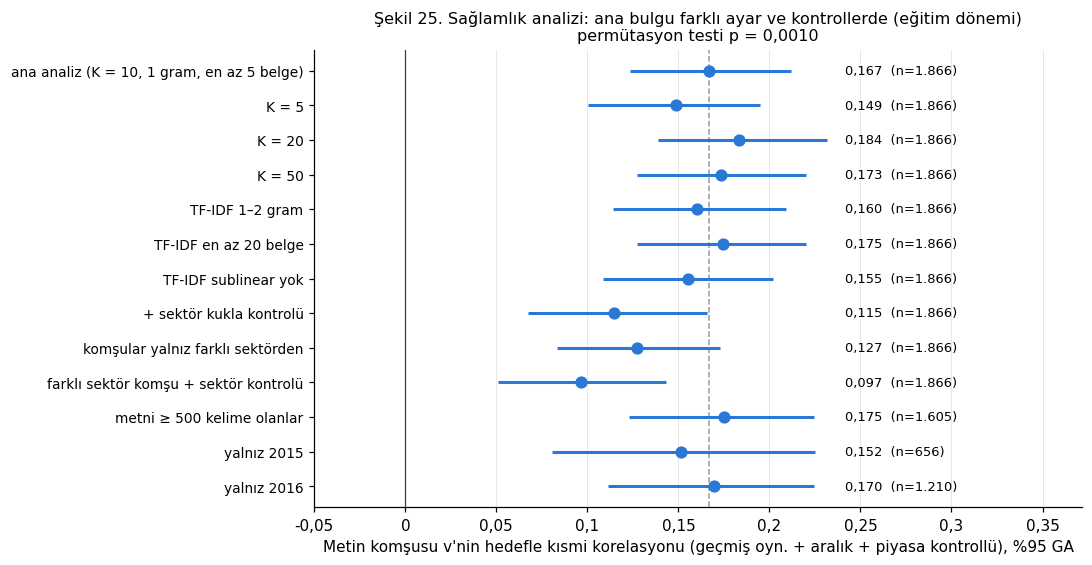

In [19]:
fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(len(saglamlik))[::-1]
ax.axvline(0, color=KOYU, lw=0.8)
ax.axvline(saglamlik["kısmi ρ"].iloc[0], color=GRI, lw=1, ls="--")
ax.hlines(y, saglamlik["%95 GA alt"], saglamlik["%95 GA üst"], color=MAVI, lw=2)
ax.plot(saglamlik["kısmi ρ"], y, "o", color=MAVI, ms=7)
for yi, (r, n) in zip(y, zip(saglamlik["kısmi ρ"], saglamlik["n"])):
    ax.text(saglamlik["%95 GA üst"].max() + 0.01, yi, f"{tr(r, 3)}  (n={tr(n)})", va="center", fontsize=8.5)
ax.set_yticks(y, saglamlik.varyant, fontsize=9)
ax.set_xlim(min(-0.05, saglamlik["%95 GA alt"].min() - 0.02), saglamlik["%95 GA üst"].max() + 0.14)
ax.xaxis.set_major_formatter(VIRGUL)
ax.set_xlabel("Metin komşusu v'nin hedefle kısmi korelasyonu (geçmiş oyn. + aralık + piyasa kontrollü), %95 GA")
ax.grid(axis="y", visible=False)
ax.set_title(f"Şekil 25. Sağlamlık analizi: ana bulgu farklı ayar ve kontrollerde (eğitim dönemi)\npermütasyon testi p = {tr(p_perm, 4)}", fontsize=10.5)
kaydet(fig, "f3_11_saglamlik")
plt.show()

In [20]:
# Sözlük sonucu yasal uyarı kalıp metninden mi kaynaklanıyor? Bu cümleler çıkarılıp sözlük oranları yeniden hesaplanır.
kalip = re.compile(r"forward-looking|safe harbor|risks and uncertainties|actual results (?:may|could) differ|non-gaap", re.I)
cum_e = t.set_index("klasor").loc[e.klasor, "cumleler_temiz"]
ayiklanmis = [[s for s in cs if not kalip.search(s)] for cs in cum_e]
print(f"Çıkarılan kalıp cümle: {sum(len(a) - len(b) for a, b in zip(cum_e, ayiklanmis)):,} "
      f"({100 * sum(len(a) - len(b) for a, b in zip(cum_e, ayiklanmis)) / sum(len(a) for a in cum_e):.2f}%)")
lm2 = ozellik.metin_ozellikleri(ayiklanmis, sozluk)
for k in ["belirsizlik", "olumsuz", "net_ton"]:
    e2 = e.assign(**{k: lm2[k].to_numpy()})
    H, p, eps = kw(e2, k)
    print(f"{k:12s} kalıp çıkarılmış: Spearman(v) = {stats.spearmanr(e2[k], e2.v)[0]:+.3f} | KW ε² = {eps:.4f} | "
          f"kısmi ρ (fiyat kontrollü) = {kismi(e2, k, 'v', ['gecmis_oyn_60', 'aralik_ort']):+.3f}")

Çıkarılan kalıp cümle: 1,187 (0.65%)


belirsizlik  kalıp çıkarılmış: Spearman(v) = -0.063 | KW ε² = 0.0013 | kısmi ρ (fiyat kontrollü) = -0.083
olumsuz      kalıp çıkarılmış: Spearman(v) = +0.010 | KW ε² = 0.0017 | kısmi ρ (fiyat kontrollü) = -0.020
net_ton      kalıp çıkarılmış: Spearman(v) = -0.022 | KW ε² = 0.0007 | kısmi ρ (fiyat kontrollü) = +0.015


**Ne gözlendi:** 13 varyantın hepsinde kısmi korelasyon pozitif ve hiçbir güven aralığı sıfırı içermiyor (0,097–0,184).
Komşu sayısı (K = 5: 0,149; 20: 0,184; 50: 0,173) ve TF-IDF ayarları (0,155–0,175) sonucu çok az değiştiriyor. Sektör kukla
değişkenleri kontrol edilince 0,115 (0,068–0,166); komşular yalnız farklı sektörlerden seçilince 0,127; ikisi birlikte
0,097 (0,051–0,143). Uzun metinlerde (≥ 500 kelime) 0,175; 2015'te 0,152, 2016'da 0,170. Permütasyon testinde "metin bilgisi
yok" dağılımının ortalaması 0,001, en büyük değeri 0,121; gözlenen 0,167 hepsinin üstünde (p = 0,001, 1.000 permütasyonla
ulaşılabilen en küçük değer). Yasal uyarı kalıp cümleleri (1.187 cümle, %0,65) çıkarıldığında da sözlük özellikleri
hedefle ilişkisiz kalıyor (belirsizlik ρ = −0,063, olumsuz 0,010, net ton −0,022).

**Neden önemli:** Ana bulgu bir ayar seçiminin ya da şansın ürünü değil. Sektör, metin sinyalinin bir kısmını açıklıyor
(kontrol edilince etki yaklaşık %25–40 azalıyor) ama sektörün ötesinde anlamlı bir katkı kalıyor; yani metin yalnız "hangi
sektör" bilgisini taşımıyor. Sözlük sonucunun olumsuz çıkması da kalıp metinden kaynaklanmıyor.

**Sonraki aşamaya etkisi:** Final modelinde ablasyon sektör bilgisi de verilerek yapılmalı (fiyat + sektör ile fiyat + sektör
+ metin karşılaştırması); metnin gerçek katkısı bu farkla ölçülür.

## 10. Kısa değerlendirme

**Öne çıkan bulgular**
1. Fiyat modalitesi güçlü bir taban: gün içi aralık (ε² = 0,247) ve geçmiş oynaklık (ε² = 0,204) sınıfları açıkça ayırıyor.
2. Sözlük temelli ton (LM belirsizlik, olumsuzluk, net ton) bu veride oynaklıkla neredeyse ilişkisiz; metnin bilgisi içerikte (ürün/satış dili, sektör).
3. Metin, fiyatın üzerine bilgi ekliyor: benzer metinli başka şirketlerin oynaklığı, fiyat ve piyasa kontrol edildikten sonra da hedefle ilişkili (kısmi ρ = 0,167; %95 GA 0,123–0,212). Aynı fiyat geçmişinde metin sinyali yüksek oynaklık payını yaklaşık 9–24 yüzde puan değiştiriyor. Bulgu 13 sağlamlık varyantında ve permütasyon testinde (p = 0,001) korunuyor; sektör kontrol edilince küçülüyor ama kalıyor (0,097–0,127).
4. Vakalar iki modalitenin birbirini tamamladığını somutlaştırıyor (LXU'yu fiyat, BGFV'yi metin öngörebilirdi).

**Sınırlılıklar:** metin sinyalinin bir kısmı sektör bilgisi (etki sektör kontrolüyle yaklaşık %25–40 azalıyor); hedefin bir kısmı piyasa havası; dönemler arası kayma (piyasa daha sakin, metinler daha uzun); sözlük sayımları kalıp metinle şişiyor.

**Sonraki adım (Faz 4):** şirkete göre gruplu 5 kat ve zamana göre bölme (ambargo ile); her fold'un eşik ve sözlüğünün yalnız kendi eğitim kısmından öğrenilmesi; her modalitenin model girdi biçiminin örneklerle gösterilmesi.